# SH 2-71 investigation

We start by defining some constants and importing the necessary libraries.

In [1]:
from astropy.coordinates import SkyCoord
import lightkurve as lk
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import astropy.units as u
%matplotlib inline

import cencalib as cl

data = cl.DataRetrieving(
    coords=SkyCoord("285.5 +2.156388", unit=("deg", "deg")),
    cutout_size=(20, 20),
    quality_mask="default"
)

d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
print(data.search)

SearchResult containing 2 data products.

 #     mission     year  author exptime   target_name   distance
                                   s                     arcsec 
--- -------------- ---- ------- ------- --------------- --------
  0 TESS Sector 54 2022 TESScut     475 285.5, 2.156388      0.0
  1 TESS Sector 80 2024 TESScut     158 285.5, 2.156388      0.0


PARAMETERS SECTION

We need to understand four parameters:

TIMEDEL:
Cadence/time resolution of the final data, expressed in days.
This represents approximately how much time separates one stored flux measurement
from the next one.

This is the most useful parameter for defining the sampling cadence of the
light curve.

FRAMETIM:
Frame time in seconds.
This is the total duration associated with one individual detector frame.

FRAMETIM includes both:
    - INT_TIME: photon accumulation time
    - READTIME: detector readout time

Therefore:

    FRAMETIM = INT_TIME + READTIME

We do not directly analyze these individual frames because several frames are
combined to produce each point in the final light curve.

INT_TIME:
Integration time in seconds for ONE individual frame.
This is the time during which the detector is actually accumulating photons.

It is NOT the time resolution of the final light curve.

NUM_FRM:
Number of individual frames used to construct one timestamp/cadence.

Therefore:

    nominal cadence ≈ FRAMETIM × NUM_FRM

while:

    total possible photon integration = INT_TIME × NUM_FRM

For these TESS products, onboard cosmic-ray mitigation removes the highest and
lowest value in every group of 10 frames. Therefore, effectively 8 out of every
10 frames contribute to the final flux.

Thus:

    effective exposure ≈ INT_TIME × NUM_FRM × 0.8

TIMEDEL should approximately correspond to the cadence:

    cadence_seconds = TIMEDEL × 86400

In [3]:
a_parameters = cl.get_tpf_parameters(data.get_aristoteles_file())
b_parameters = cl.get_tpf_parameters(data.get_bethesda_file())

a_timedel = a_parameters["timedel"]
a_frametim = a_parameters["frametim"]
a_num_frm = a_parameters["num_frm"]
a_int_time = a_parameters["int_time"]

b_timedel = b_parameters["timedel"]
b_frametim = b_parameters["frametim"]
b_num_frm = b_parameters["num_frm"]
b_int_time = b_parameters["int_time"]

print("Aristoteles parameters:")
print(f"TIMEDEL: {a_timedel} days")
print(f"FRAMETIM: {a_frametim} seconds")
print(f"NUM_FRM: {a_num_frm}")
print(f"INT_TIME: {a_int_time} seconds")

print("\nBethesda parameters:")
print(f"TIMEDEL: {b_timedel} days")
print(f"FRAMETIM: {b_frametim} seconds")
print(f"NUM_FRM: {b_num_frm}")
print(f"INT_TIME: {b_int_time} seconds")


Aristoteles parameters:
TIMEDEL: 0.006944444444444444 days
FRAMETIM: 2.0 seconds
NUM_FRM: 300
INT_TIME: 1.98 seconds

Bethesda parameters:
TIMEDEL: 0.0023148148148148 days
FRAMETIM: 2.0 seconds
NUM_FRM: 100
INT_TIME: 1.98 seconds


In [4]:
a_exposure = cl.get_exposure_summary(data.get_aristoteles_file())
b_exposure = cl.get_exposure_summary(data.get_bethesda_file())

a_cadence_time = a_exposure["cadence"]
a_raw_integration = a_exposure["raw_integration"]
a_exposure_time = a_exposure["effective_exposure"]

b_cadence_time = b_exposure["cadence"]
b_raw_integration = b_exposure["raw_integration"]
b_exposure_time = b_exposure["effective_exposure"]

print("Aristoteles:")
print(f"Cadence: {a_cadence_time} s")
print(f"Raw integration: {a_raw_integration} s")
print(f"Effective exposure: {a_exposure_time} s")

print("\nBethesda:")
print(f"Cadence: {b_cadence_time} s")
print(f"Raw integration: {b_raw_integration} s")
print(f"Effective exposure: {b_exposure_time} s")


Aristoteles:
Cadence: 600.0 s
Raw integration: 594.0 s
Effective exposure: 475.20000000000005 s

Bethesda:
Cadence: 200.0 s
Raw integration: 198.0 s
Effective exposure: 158.4 s


## Files

In [5]:
aristoteles = data.get_aristoteles_file()
bethesda = data.get_bethesda_file()

## Mask definition


In [6]:
# to decide the pixels we will cover we take in count the size of the PN
# which is 2.1 arcmin, so having that tess pixels are 21 arcsec we need to cover 6x6 pixels

aperture_small = np.zeros(data.get_aristoteles_file().shape[1:], dtype=bool)
aperture_big = np.zeros(data.get_aristoteles_file().shape[1:], dtype=bool)
aperture_small[9:12, 9:12] = True
aperture_big[8:14, 8:13] = True


In [7]:
aristoteles_mean = data.get_aristoteles_file().flux.mean(axis=(0)).value
bethesda_mean = data.get_bethesda_file().flux.mean(axis=(0)).value

aristoteles_mean_masked_small = np.ma.masked_array(aristoteles_mean, mask=~aperture_small)
aristoteles_mean_masked_big = np.ma.masked_array(aristoteles_mean, mask=~aperture_big)
bethesda_mean_masked_small = np.ma.masked_array(bethesda_mean, mask=~aperture_small)
bethesda_mean_masked_big = np.ma.masked_array(bethesda_mean, mask=~aperture_big)

print(f"Aristoteles small mean flux (masked): {aristoteles_mean_masked_small.mean()}")
print(f"Aristoteles big mean flux (masked): {aristoteles_mean_masked_big.mean()}")
print(f"Bethesda mean small flux (masked): {bethesda_mean_masked_small.mean()}")
print(f"Bethesda mean big flux (masked): {bethesda_mean_masked_big.mean()}")

Aristoteles small mean flux (masked): 908.2721896701389
Aristoteles big mean flux (masked): 761.621484375
Bethesda mean small flux (masked): 1903.2039930555557
Bethesda mean big flux (masked): 1739.7837239583334


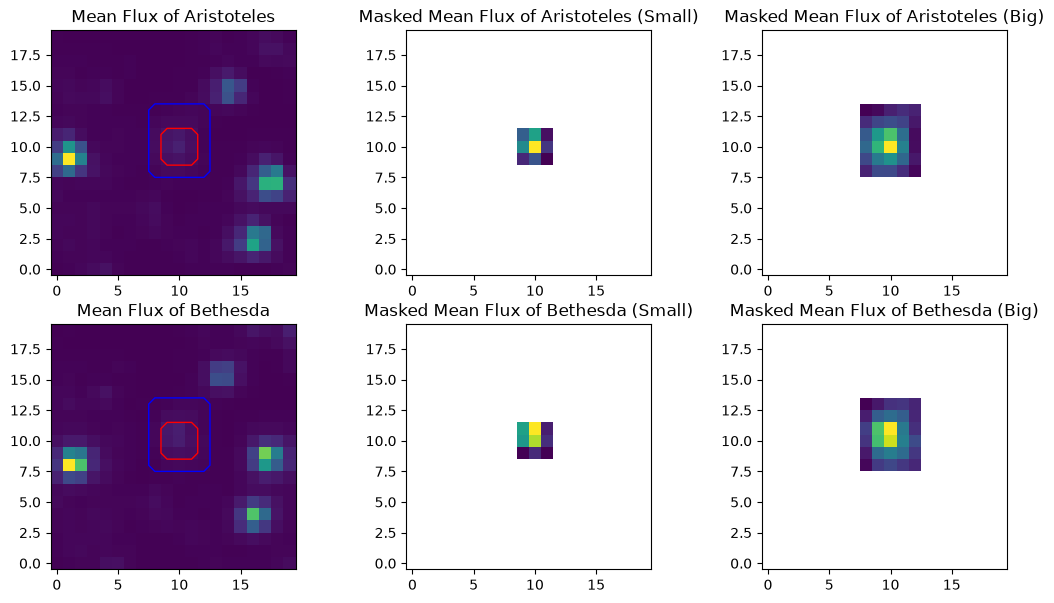

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(13, 7))

# aristoteles

ax[0, 0].imshow(aristoteles_mean, origin='lower', cmap='viridis')
ax[0, 0].set_title('Mean Flux of Aristoteles')
ax[0, 0].contour(aperture_small, colors='red', linewidths=1)
ax[0, 0].contour(aperture_big, colors='blue', linewidths=1)

ax[0, 1].imshow(aristoteles_mean_masked_small, origin='lower', cmap='viridis')
ax[0, 1].set_title('Masked Mean Flux of Aristoteles (Small)')

ax[0, 2].imshow(aristoteles_mean_masked_big, origin='lower', cmap='viridis')
ax[0, 2].set_title('Masked Mean Flux of Aristoteles (Big)')

# bethesda

ax[1, 0].imshow(bethesda_mean, origin='lower', cmap='viridis')
ax[1, 0].set_title('Mean Flux of Bethesda')
ax[1, 0].contour(aperture_small, colors='red', linewidths=1)
ax[1, 0].contour(aperture_big, colors='blue', linewidths=1)

ax[1, 1].imshow(bethesda_mean_masked_small, origin='lower', cmap='viridis')
ax[1, 1].set_title('Masked Mean Flux of Bethesda (Small)')

ax[1, 2].imshow(bethesda_mean_masked_big, origin='lower', cmap='viridis')
ax[1, 2].set_title('Masked Mean Flux of Bethesda (Big)')

plt.show()

## LightCurves definitions and initialization
First we start with simple light curves, with sap taking the entire aperture and some with only the aperture we use for sh 2 71

In [9]:
lc_aristoteles_default = data.get_aristoteles_file().to_lightcurve()
lc_bethesda_default = bethesda.to_lightcurve()

In [10]:
if aristoteles is None or bethesda is None:
    raise ValueError("One or both of the files are None. Please check the downloaded files.")

if not isinstance(aristoteles, lk.TessTargetPixelFile) or not isinstance(bethesda, lk.TessTargetPixelFile):
    raise TypeError("One or both of the files are not of type TessTargetPixelFile.")

lcs_aperture_small = {
    'aristoteles': {
        "sum": aristoteles.to_lightcurve(method='sap', aperture_mask=aperture_small, flux_method='sum'),
        "mean": aristoteles.to_lightcurve(method='sap', aperture_mask=aperture_small, flux_method='mean')
    },
    'bethesda': {
        "sum": bethesda.to_lightcurve(method='sap', aperture_mask=aperture_small, flux_method='sum'),
        "mean": bethesda.to_lightcurve(method='sap', aperture_mask=aperture_small, flux_method='mean')
    }
}

lcs_aperture_big = {
    'aristoteles': {
        "sum": aristoteles.to_lightcurve(method='sap', aperture_mask=aperture_big, flux_method='sum'),
        "mean": aristoteles.to_lightcurve(method='sap', aperture_mask=aperture_big, flux_method='mean')
    },
    'bethesda': {
        "sum": bethesda.to_lightcurve(method='sap', aperture_mask=aperture_big, flux_method='sum'),
        "mean": bethesda.to_lightcurve(method='sap', aperture_mask=aperture_big, flux_method='mean')
    }
}

## background noise removal

In [11]:
def calculate_bg_mask(file, aperture_mask, threshold=0.1):
    aperture_mask = np.asarray(aperture_mask, dtype=bool)

    file_bg_mask = ~file.create_threshold_mask(
        threshold=threshold, reference_pixel=None
    )
    file_bg_mask = np.logical_and(file_bg_mask, ~aperture_mask)

    return file_bg_mask

def plot_bg_mask(file, bg_mask, title):
    plt.figure(figsize=(6, 6))
    plt.imshow(file.flux.value[0], origin='lower', cmap='viridis')
    plt.contour(bg_mask, colors='red', linewidths=1)
    plt.title(title)
    plt.colorbar(label='Flux')
    plt.show()

In [12]:
aristoteles_bg_mask = calculate_bg_mask(aristoteles, aperture_small)
bethesda_bg_mask = calculate_bg_mask(bethesda, aperture_small)

In [13]:
# now for each cadence we need to take the mean of the pixels in the bg mask
aristoteles_bg_mask_mean = np.mean(aristoteles.flux[:, aristoteles_bg_mask], axis=1)
bethesda_bg_mask_mean = np.mean(bethesda.flux[:, bethesda_bg_mask], axis=1)

print(aristoteles_bg_mask_mean.shape)
print(aristoteles_bg_mask_mean)

print(bethesda_bg_mask_mean.shape)
print(bethesda_bg_mask_mean)

(2781,)
[229.81783 230.00288 230.11006 ... 226.23935 226.3678  226.48839] electron / s
(10399,)
[252.2667  252.13182 252.02165 ... 253.26878 253.07164 253.03186] electron / s


In [15]:

lc_aristoteles_sap_bg_corrected = lcs_aperture_small["aristoteles"]["sum"].copy()
lc_aristoteles_sap_bg_corrected.flux = lcs_aperture_small["aristoteles"]["sum"].flux - aristoteles_bg_mask_mean

lc_bethesda_sap_bg_corrected = lcs_aperture_small["bethesda"]["sum"].copy()
lc_bethesda_sap_bg_corrected.flux = lcs_aperture_small["bethesda"]["sum"].flux - bethesda_bg_mask_mean

Now that we have the bg noise we remove that noise from the cbvs corrected light curves, we should subtract for each cadence the meaned background flux from the cbvs corrected flux

Text(0, 0.5, 'Flux (Background Subtracted)')

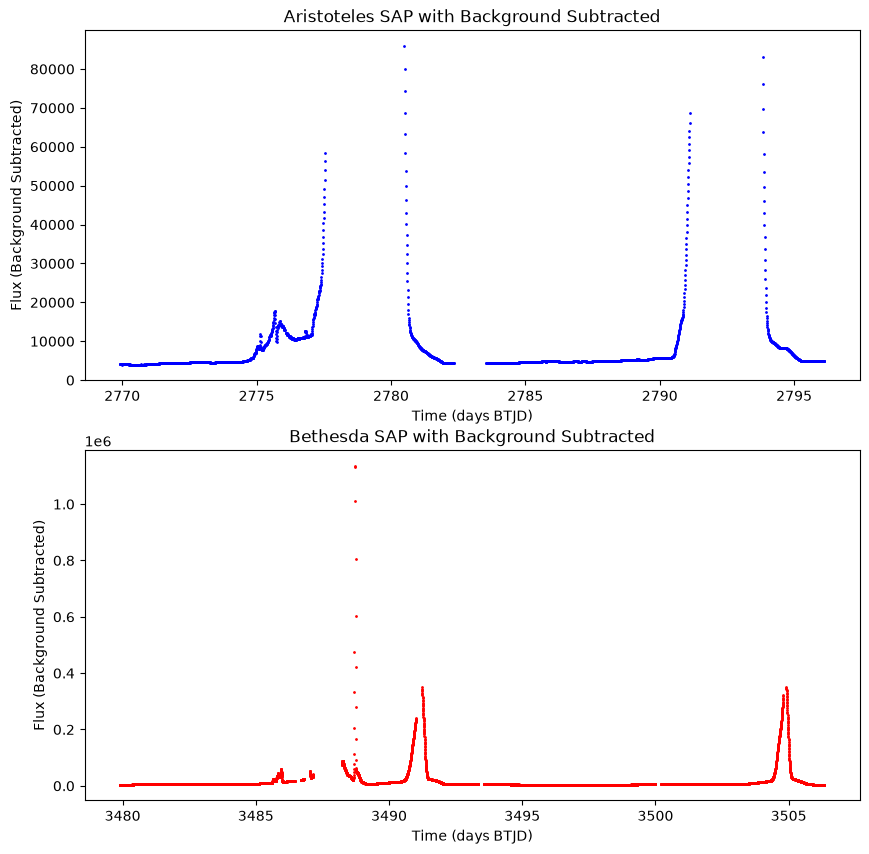

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(10, 10))
ax[0].scatter(lc_aristoteles_sap_bg_corrected.time.value, lc_aristoteles_sap_bg_corrected.flux.value, color='blue', s=1)
ax[0].set_title('Aristoteles SAP with Background Subtracted')
ax[0].set_xlabel('Time (days BTJD)')
ax[0].set_ylabel('Flux (Background Subtracted)')

ax[1].scatter(lc_bethesda_sap_bg_corrected.time.value, lc_bethesda_sap_bg_corrected.flux.value, color='red', s=1)
ax[1].set_title('Bethesda SAP with Background Subtracted')
ax[1].set_xlabel('Time (days BTJD)')
ax[1].set_ylabel('Flux (Background Subtracted)')

So, at this point we have the light curve `lc_aristoteles_sap_bg_corrected` and `lc_bethesda_sap_bg_corrected` which are the light curves where we applied a sap using the nebula aperture mask then we subtracted the meaned background flux (of each cadence)

## correctors
Here we apply some correctors to the light curves, first with CBVs, currently we are working with the meaned light curve over the aperture mask defined above, but we can also use the sumed light curve, or the entire aperture light curve.

Also we use SingleScale because we want to take in count every single CBV and maintain the long term trends

In [21]:
# Fix urllib SSL certificates for Lightkurve CBV downloads in case of SSL errors

if True:
    import ssl
    import certifi
    import urllib.request

    ssl_context = ssl.create_default_context(
        cafile=certifi.where()
    )

    urllib.request.install_opener(
        urllib.request.build_opener(
            urllib.request.HTTPSHandler(
                context=ssl_context
            )
        )
    )

In [22]:
aristoteles_corr_cbvs = lc_aristoteles_sap_bg_corrected.to_corrector(method='cbv', interpolate_cbvs=True, extrapolate_cbvs=True)
bethesda_corr_cbvs = lc_bethesda_sap_bg_corrected.to_corrector(method='cbv', interpolate_cbvs=True, extrapolate_cbvs=True)

Aristoteles CBVS Corrector (5): [TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType : SingleScale, nCBVS : 16, TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType.Band: MultiScale.1, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType.Band: MultiScale.2, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType.Band: MultiScale.3, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 54.1.2, CBVType : Spike, nCBVS : 8]
Bethesda CBVS Corrector (5): [TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType : SingleScale, nCBVS : 16, TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType.Band: MultiScale.1, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType.Band: MultiScale.2, nCBVs : 8, TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType.Band: MultiScale.3, nCBVs : 7, TESS CBVs, Sector.Camera.CCD : 80.1.1, CBVType : Spike, nCBVS : 8]


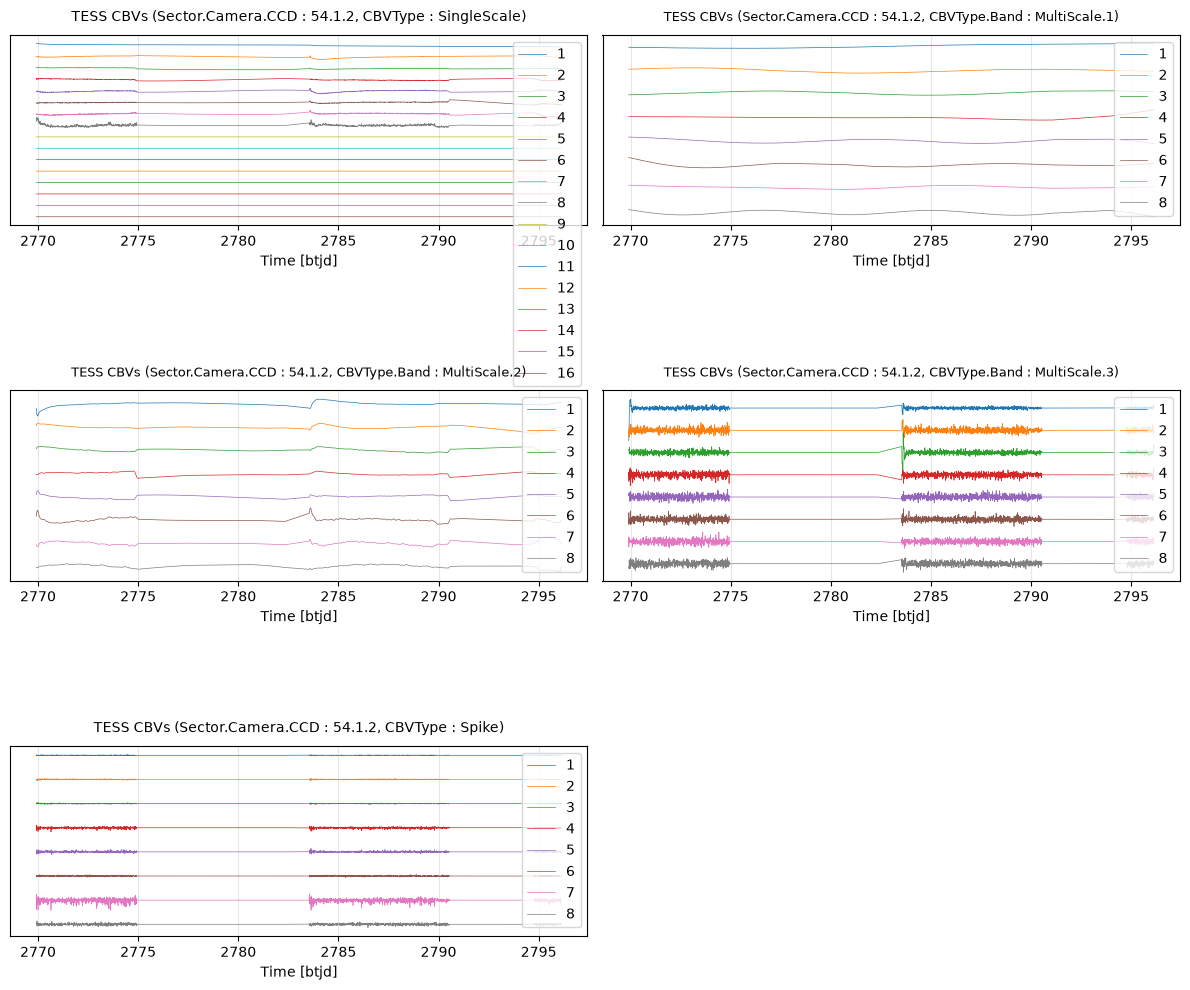

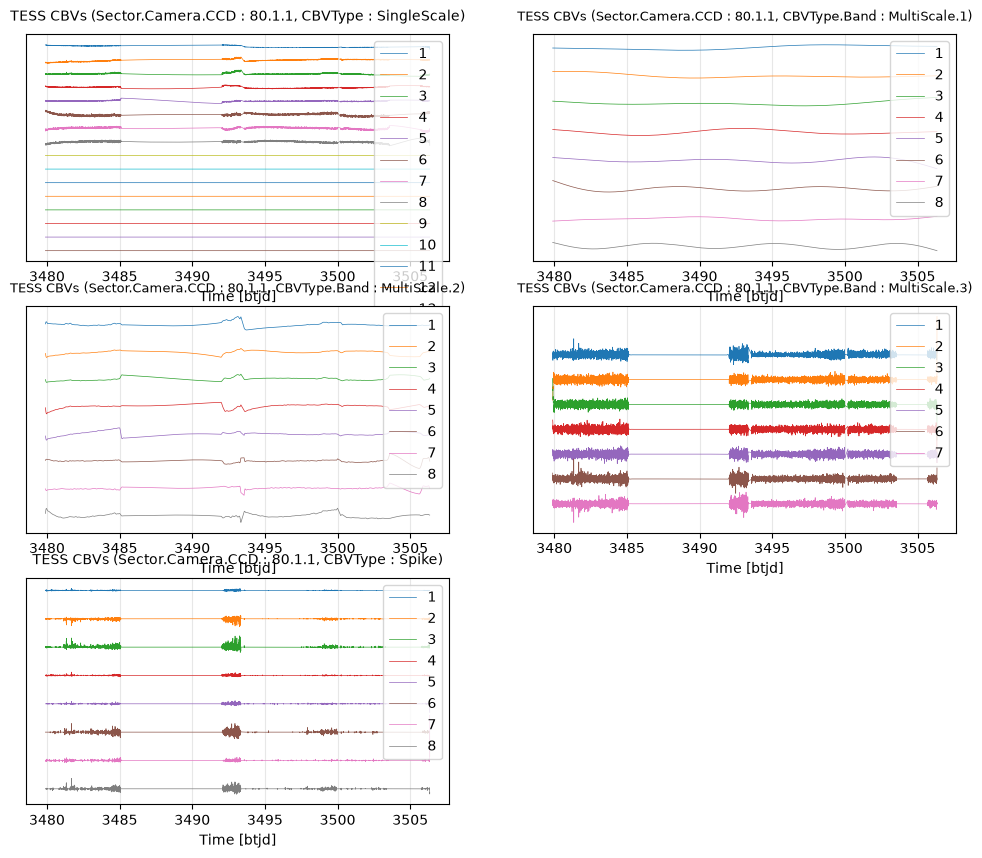

In [23]:
print(f"Aristoteles CBVS Corrector ({len(aristoteles_corr_cbvs.cbvs)}):", aristoteles_corr_cbvs.cbvs)
print(f"Bethesda CBVS Corrector ({len(bethesda_corr_cbvs.cbvs)}):", bethesda_corr_cbvs.cbvs)

fig_ari, axa = plt.subplots(3, 2, figsize=(12, 10))
axa = axa.flatten() 

for i, cbv in enumerate(aristoteles_corr_cbvs.cbvs):
    cbv.plot(ax=axa[i])
    axa[i].legend(loc='upper right')

axa[5].set_visible(False)

fig_ari.tight_layout()


fig_bet, axb = plt.subplots(3, 2, figsize=(12, 10))
axb = axb.flatten()

for i, cbv in enumerate(bethesda_corr_cbvs.cbvs):
    cbv.plot(ax=axb[i])
    axb[i].legend(loc='upper right')

axb[5].set_visible(False)

plt.show()

In [24]:
lc_aristoteles_ss_cbvs = aristoteles_corr_cbvs.correct(cbv_type=['SingleScale'], cbv_indices=[np.arange(1, 8)])
lc_bethesda_ss_cbvs = bethesda_corr_cbvs.correct(cbv_type=['SingleScale'], cbv_indices=[np.arange(1, 8)])

Optimized Over-fitting metric: 0.999638451892391
Optimized Under-fitting metric: 0.9067012614876193
Optimized Alpha: 9.162e+03


d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(
d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(
d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warning

Optimized Over-fitting metric: 0.9994834347959259
Optimized Under-fitting metric: 0.8373825158729306
Optimized Alpha: 9.988e+03


In [25]:
lc_aristoteles_spike_cbvs = aristoteles_corr_cbvs.correct(cbv_type=['Spike'], cbv_indices=[np.arange(1, 8)])
lc_bethesda_spike_cbvs = bethesda_corr_cbvs.correct(cbv_type=['Spike'], cbv_indices=[np.arange(1, 8)])

Optimized Over-fitting metric: 0.9989207651085982
Optimized Under-fitting metric: 0.9067006894468675
Optimized Alpha: 8.934e+03


d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(
d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(
d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warning

Optimized Over-fitting metric: 0.9999711890233735
Optimized Under-fitting metric: 0.8373819494491859
Optimized Alpha: 1.773e+03


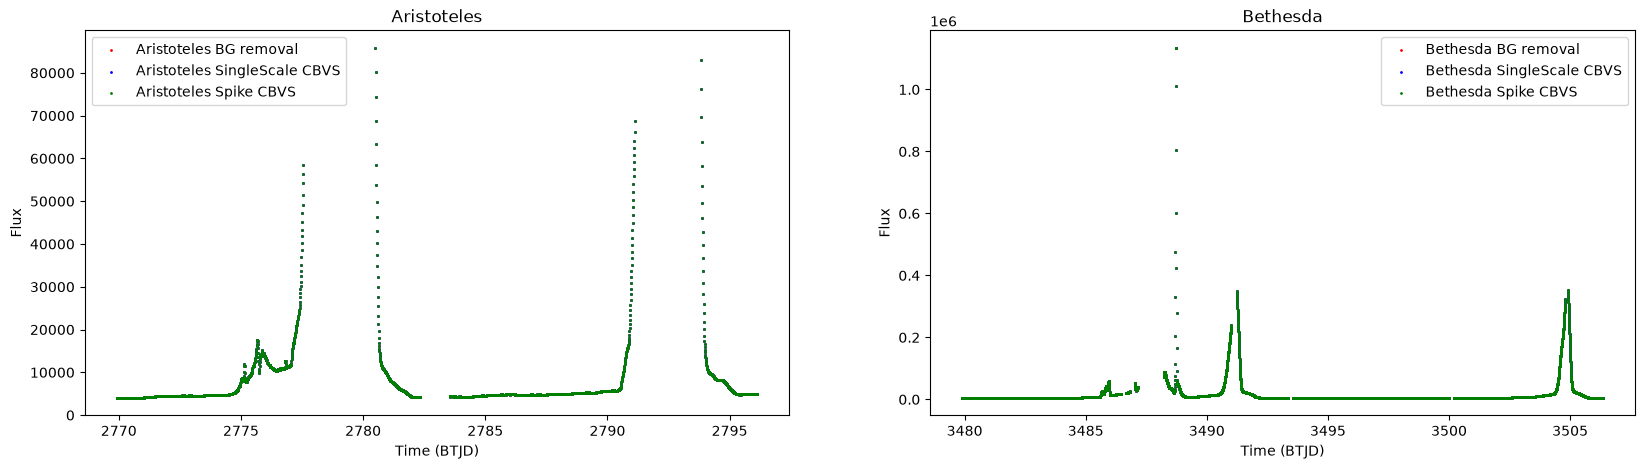

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(20, 5))

ax[0].scatter(lc_aristoteles_sap_bg_corrected.time.value, lc_aristoteles_sap_bg_corrected.flux.value, color='red', label='Aristoteles BG removal', s=1)
ax[0].scatter(lc_aristoteles_ss_cbvs.time.value, lc_aristoteles_ss_cbvs.flux.value, color='blue', label='Aristoteles SingleScale CBVS', s=1)
ax[0].scatter(lc_aristoteles_spike_cbvs.time.value, lc_aristoteles_spike_cbvs.flux.value, color='green', label='Aristoteles Spike CBVS', s=1)
ax[0].set_xlabel('Time (BTJD)')
ax[0].set_ylabel('Flux')
ax[0].set_title('Aristoteles')
ax[0].legend()

ax[1].scatter(lc_bethesda_sap_bg_corrected.time.value, lc_bethesda_sap_bg_corrected.flux.value, color='red', label='Bethesda BG removal', s=1)
ax[1].scatter(lc_bethesda_ss_cbvs.time.value, lc_bethesda_ss_cbvs.flux.value, color='blue', label='Bethesda SingleScale CBVS', s=1)
ax[1].scatter(lc_bethesda_spike_cbvs.time.value, lc_bethesda_spike_cbvs.flux.value, color='green', label='Bethesda Spike CBVS', s=1)
ax[1].set_xlabel('Time (BTJD)')
ax[1].set_ylabel('Flux')
ax[1].set_title('Bethesda')
ax[1].legend()



Based on above data the difference is minimal for aristoteles but significant for bethesda, but we still will use single scale and spike just to clean it up a bit more

In [28]:
lc_aristoteles_cbvs = aristoteles_corr_cbvs.correct(cbv_type=['SingleScale', 'Spike'], cbv_indices=[np.arange(1, 8), np.arange(1, 8)])
lc_bethesda_cbvs = bethesda_corr_cbvs.correct(cbv_type=['SingleScale', 'Spike'], cbv_indices=[np.arange(1, 8), np.arange(1, 8)])

Optimized Over-fitting metric: 0.9995786763382963
Optimized Under-fitting metric: 0.9067012333705741
Optimized Alpha: 9.684e+03


d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(
d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(
d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warning

Optimized Over-fitting metric: 0.9996046109890553
Optimized Under-fitting metric: 0.8373825252358178
Optimized Alpha: 9.880e+03


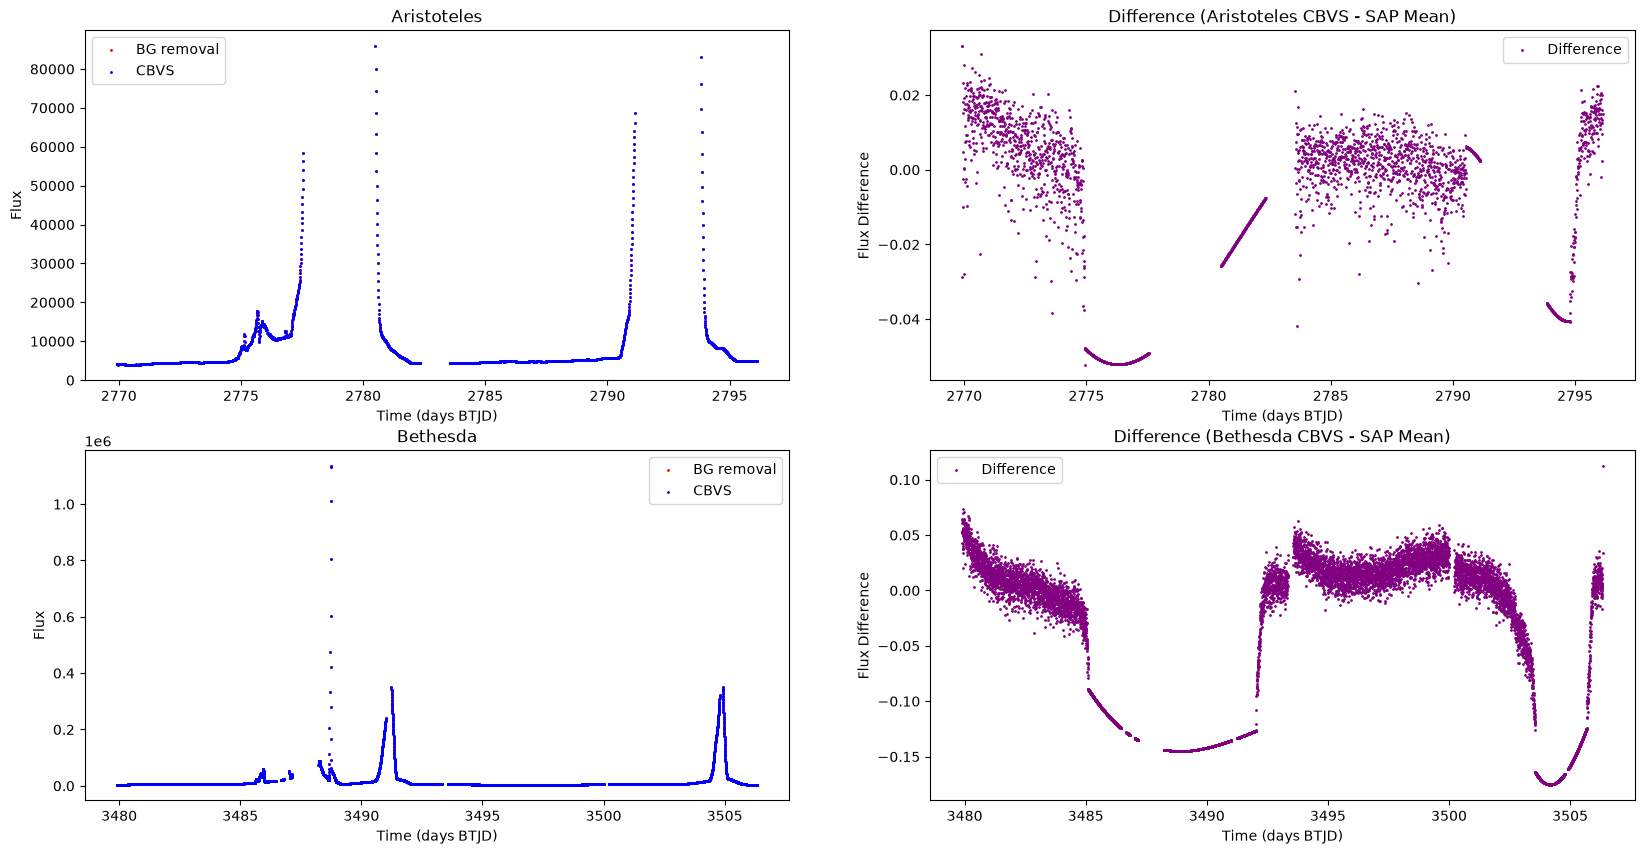

In [29]:
fig, ax = plt.subplots(2, 2, figsize=(20, 10))

# plot for comparison of lcs
ax[0, 0].scatter(lc_aristoteles_sap_bg_corrected.time.value, lc_aristoteles_sap_bg_corrected.flux.value, color='red', s=1)
ax[0, 0].scatter(lc_aristoteles_cbvs.time.value, lc_aristoteles_cbvs.flux.value, color='blue', s=1)
ax[0, 0].set_title('Aristoteles')
ax[0, 0].set_xlabel('Time (days BTJD)')
ax[0, 0].set_ylabel('Flux')
ax[0, 0].legend(['BG removal', 'CBVS'])

# difference between the two light curves
diff_aristoteles = np.subtract(lc_aristoteles_cbvs.flux.value, lc_aristoteles_sap_bg_corrected.flux.value)
ax[0, 1].scatter(lc_aristoteles_cbvs.time.value, diff_aristoteles, color='purple', s=1)
ax[0, 1].set_title('Difference (Aristoteles CBVS - SAP Mean)')
ax[0, 1].set_xlabel('Time (days BTJD)')
ax[0, 1].set_ylabel('Flux Difference')
ax[0, 1].legend(['Difference'])

ax[1, 0].scatter(lc_bethesda_sap_bg_corrected.time.value, lc_bethesda_sap_bg_corrected.flux.value, color='red', s=1)
ax[1, 0].scatter(lc_bethesda_cbvs.time.value, lc_bethesda_cbvs.flux.value, color='blue', s=1)
ax[1, 0].set_title('Bethesda')
ax[1, 0].set_xlabel('Time (days BTJD)')
ax[1, 0].set_ylabel('Flux')
ax[1, 0].legend(['BG removal', 'CBVS'])

# difference between the two light curves
diff_bethesda = np.subtract(lc_bethesda_cbvs.flux.value, lc_bethesda_sap_bg_corrected.flux.value)
ax[1, 1].scatter(lc_bethesda_cbvs.time.value, diff_bethesda, color='purple', s=1)
ax[1, 1].set_title('Difference (Bethesda CBVS - SAP Mean)')
ax[1, 1].set_xlabel('Time (days BTJD)')
ax[1, 1].set_ylabel('Flux Difference')
ax[1, 1].legend(['Difference'])

At this point we have `lc_aristoteles_cbvs` and `lc_bethesda_cbvs` where we applied sap -> bg removal -> cbvs correction

## PLD corrector comparison

In [30]:
# aristoteles_pld_corrector = aristoteles.to_corrector(method='pld')
# bethesda_pld_corrector = bethesda.to_corrector(method='pld')

aristoteles_pld_corrector_small = lk.correctors.PLDCorrector(aristoteles, aperture_mask=aperture_small)
bethesda_pld_corrector_small = lk.correctors.PLDCorrector(bethesda, aperture_mask=aperture_small)
aristoteles_pld_corrector_big = lk.correctors.PLDCorrector(aristoteles, aperture_mask=aperture_big)
bethesda_pld_corrector_big = lk.correctors.PLDCorrector(bethesda, aperture_mask=aperture_big)

In [31]:
lc_aristoteles_pld_small = aristoteles_pld_corrector_small.correct(background_aperture_mask=calculate_bg_mask(aristoteles, aperture_small))
lc_aristoteles_pld_big = aristoteles_pld_corrector_big.correct(background_aperture_mask=calculate_bg_mask(aristoteles, aperture_big))
lc_bethesda_pld_small = bethesda_pld_corrector_small.correct(background_aperture_mask=calculate_bg_mask(bethesda, aperture_small))
lc_bethesda_pld_big = bethesda_pld_corrector_big.correct(background_aperture_mask=calculate_bg_mask(bethesda, aperture_big))

array([<Axes: title={'center': 'aperture_mask'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>,
       <Axes: title={'center': 'pld_aperture_mask'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>,
       <Axes: title={'center': 'background_aperture_mask'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>],
      dtype=object)

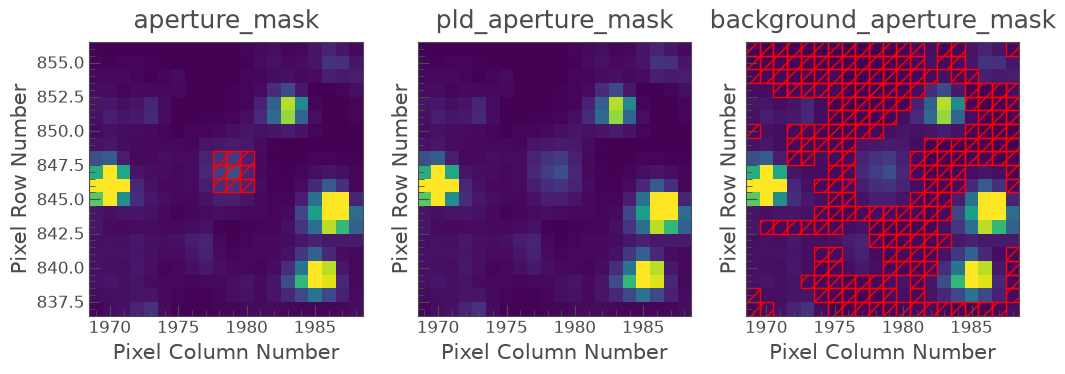

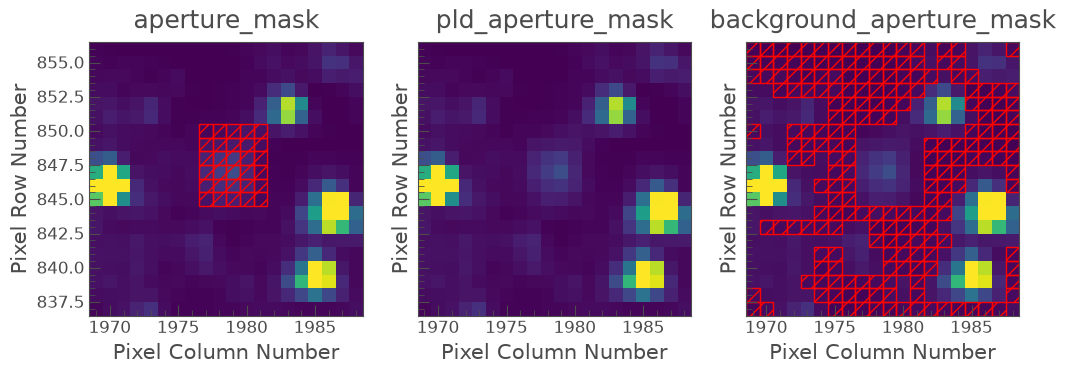

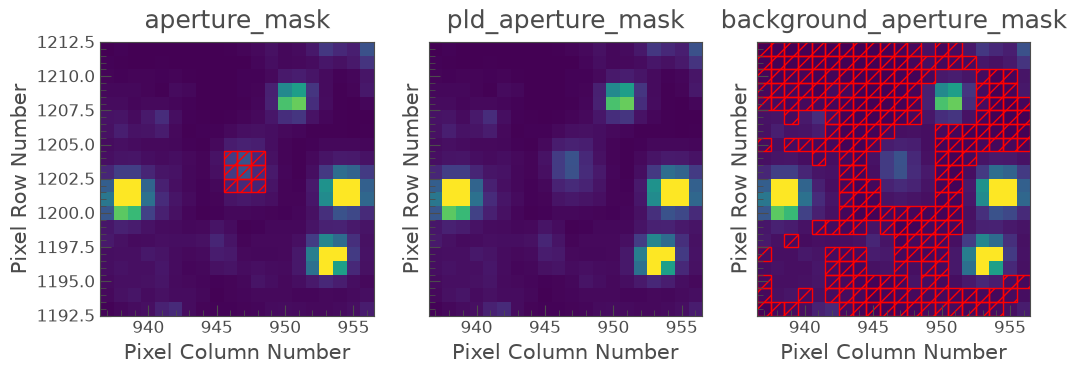

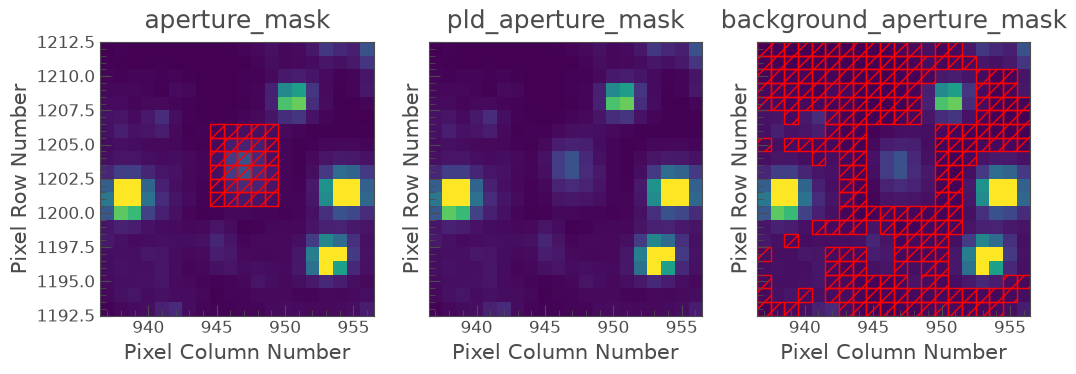

In [32]:
aristoteles_pld_corrector_small.diagnose_masks()
aristoteles_pld_corrector_big.diagnose_masks()
bethesda_pld_corrector_small.diagnose_masks()
bethesda_pld_corrector_big.diagnose_masks()

In [33]:
lc_aristoteles_pld_small = lc_aristoteles_pld_small.remove_outliers(sigma=5)
lc_aristoteles_pld_big = lc_aristoteles_pld_big.remove_outliers(sigma=5)
lc_bethesda_pld_small = lc_bethesda_pld_small.remove_outliers(sigma=5)
lc_bethesda_pld_big = lc_bethesda_pld_big.remove_outliers(sigma=5)

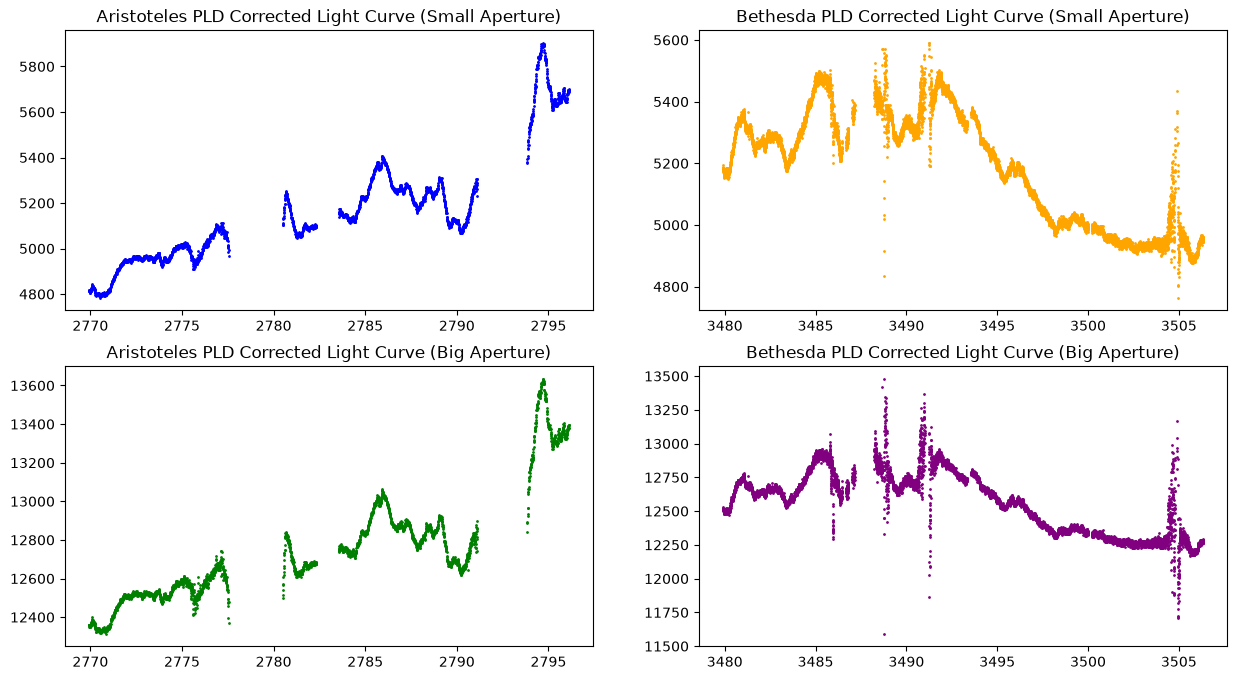

In [34]:
# lightcurves pld
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
ax[0, 0].scatter(lc_aristoteles_pld_small.time.value, lc_aristoteles_pld_small.flux.value, color='blue', s=1)
ax[0, 0].set_title('Aristoteles PLD Corrected Light Curve (Small Aperture)')

ax[1, 0].scatter(lc_aristoteles_pld_big.time.value, lc_aristoteles_pld_big.flux.value, color='green', s=1)
ax[1, 0].set_title('Aristoteles PLD Corrected Light Curve (Big Aperture)')

ax[0, 1].scatter(lc_bethesda_pld_small.time.value, lc_bethesda_pld_small.flux.value, color='orange', s=1)
ax[0, 1].set_title('Bethesda PLD Corrected Light Curve (Small Aperture)')

ax[1, 1].scatter(lc_bethesda_pld_big.time.value, lc_bethesda_pld_big.flux.value, color='purple', s=1)
ax[1, 1].set_title('Bethesda PLD Corrected Light Curve (Big Aperture)')

plt.show()

d:\Programacion\cencainternship\.cenca-venv\Lib\site-packages\lightkurve\lightcurve.py:1261: LightkurveWarning: The light curve appears to be zero-centered (median=4.95e+03 electron / s +/- 4.13e+04 electron / s); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


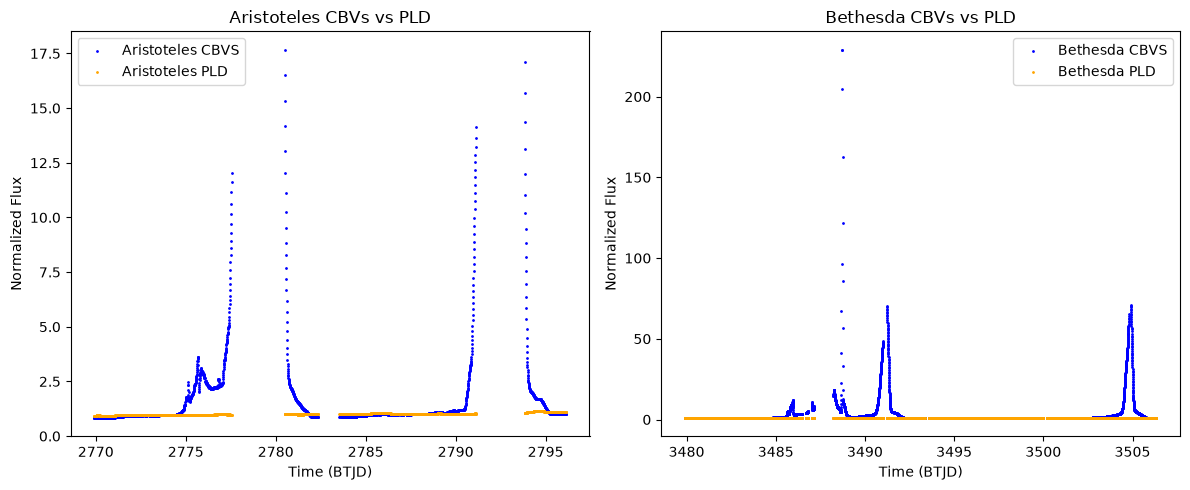

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(lc_aristoteles_cbvs.time.value, lc_aristoteles_cbvs.normalize().flux.value, color='blue', label='Aristoteles CBVS', s=1)
ax[0].scatter(lc_aristoteles_pld_small.time.value, lc_aristoteles_pld_small.normalize().flux.value, color='orange', label='Aristoteles PLD', s=1)
ax[0].set_title('Aristoteles CBVs vs PLD')
ax[0].set_xlabel('Time (BTJD)')
ax[0].set_ylabel('Normalized Flux')
ax[0].legend()

ax[1].scatter(lc_bethesda_cbvs.time.value, lc_bethesda_cbvs.normalize().flux.value, color='blue', label='Bethesda CBVS', s=1)
ax[1].scatter(lc_bethesda_pld_small.time.value, lc_bethesda_pld_small.normalize().flux.value, color='orange', label='Bethesda PLD', s=1)
ax[1].set_title('Bethesda CBVs vs PLD')
ax[1].set_xlabel('Time (BTJD)')
ax[1].set_ylabel('Normalized Flux')
ax[1].legend()

fig.tight_layout()
plt.show()

## Correctors conclusion
So to conclude correctors, to me it seems that the best approach is pld, so now we will operate over the `lc_aristoteles_pld` and `lc_bethesda_pld` light curves, which are the light curves where we applied sap -> bg removal -> pld correction

<Axes: title={'center': 'Target ID: 285.5, 2.156388, Cadence: 0'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>

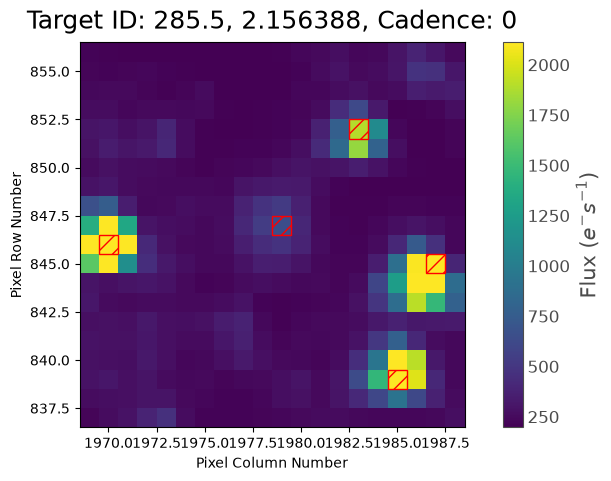

In [37]:
# for other corrections we could check trends on the entire image, for example, if the instrument has a trend to collect more 
# flux in every pixel, for that we will select some pixels and check each derivative, if the derivatives are "similar" or "equivalent"ArithmeticError

# selected pixels
pixels = [
    (9, 1),
    (10, 10),
    (8, 18),
    (2, 16),
    (15, 14)
]

pixels_mask = np.zeros(aristoteles.shape[1:], dtype=bool)
for row, col in pixels:
    pixels_mask[row, col] = True

fig, ax = plt.subplots(figsize=(10, 5))

aristoteles.plot(ax=ax, aperture_mask=pixels_mask, mask_color='red', frame=0)

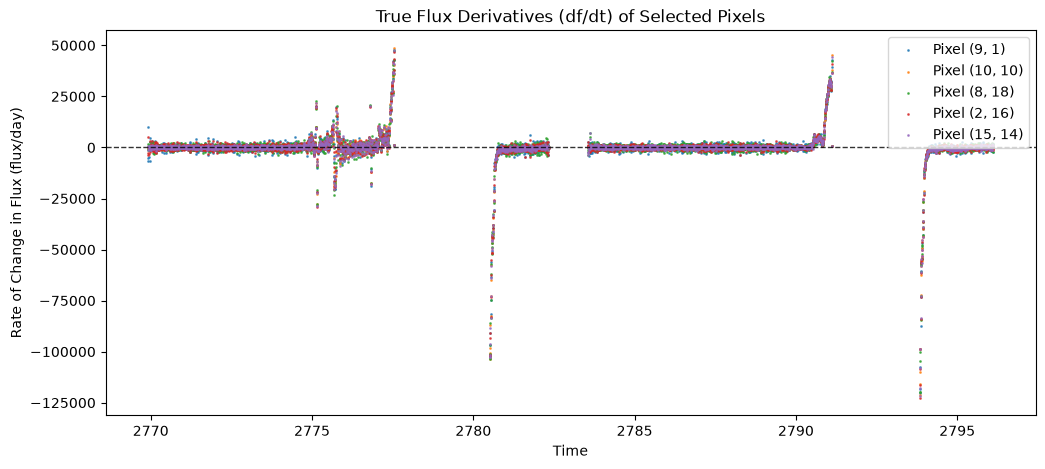

In [38]:
fig, ax = plt.subplots(figsize=(12, 5))

time = aristoteles.time.value
time_axis = time[:-1] 

# Calculate the time step array (dt)
dt = np.diff(time)

for row, col in pixels:
    single_pixel_flux = aristoteles.flux[:, row, col]
    
    # change in flux (df)
    df = np.diff(single_pixel_flux)
    
    # temporal derivative
    true_derivative = df / dt
    
    ax.scatter(time_axis, true_derivative, label=f"Pixel ({row}, {col})", alpha=0.7, s=1)

ax.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.8)
ax.set_title("True Flux Derivatives (df/dt) of Selected Pixels")
ax.set_xlabel("Time")
ax.set_ylabel("Rate of Change in Flux (flux/day)")
ax.legend(loc='upper right')

plt.show()

# Analysis
Since now we have more or less clean light curves, we can start by analyzing them, one method is FFT

In [39]:
from cencalib import fft_lightcurve


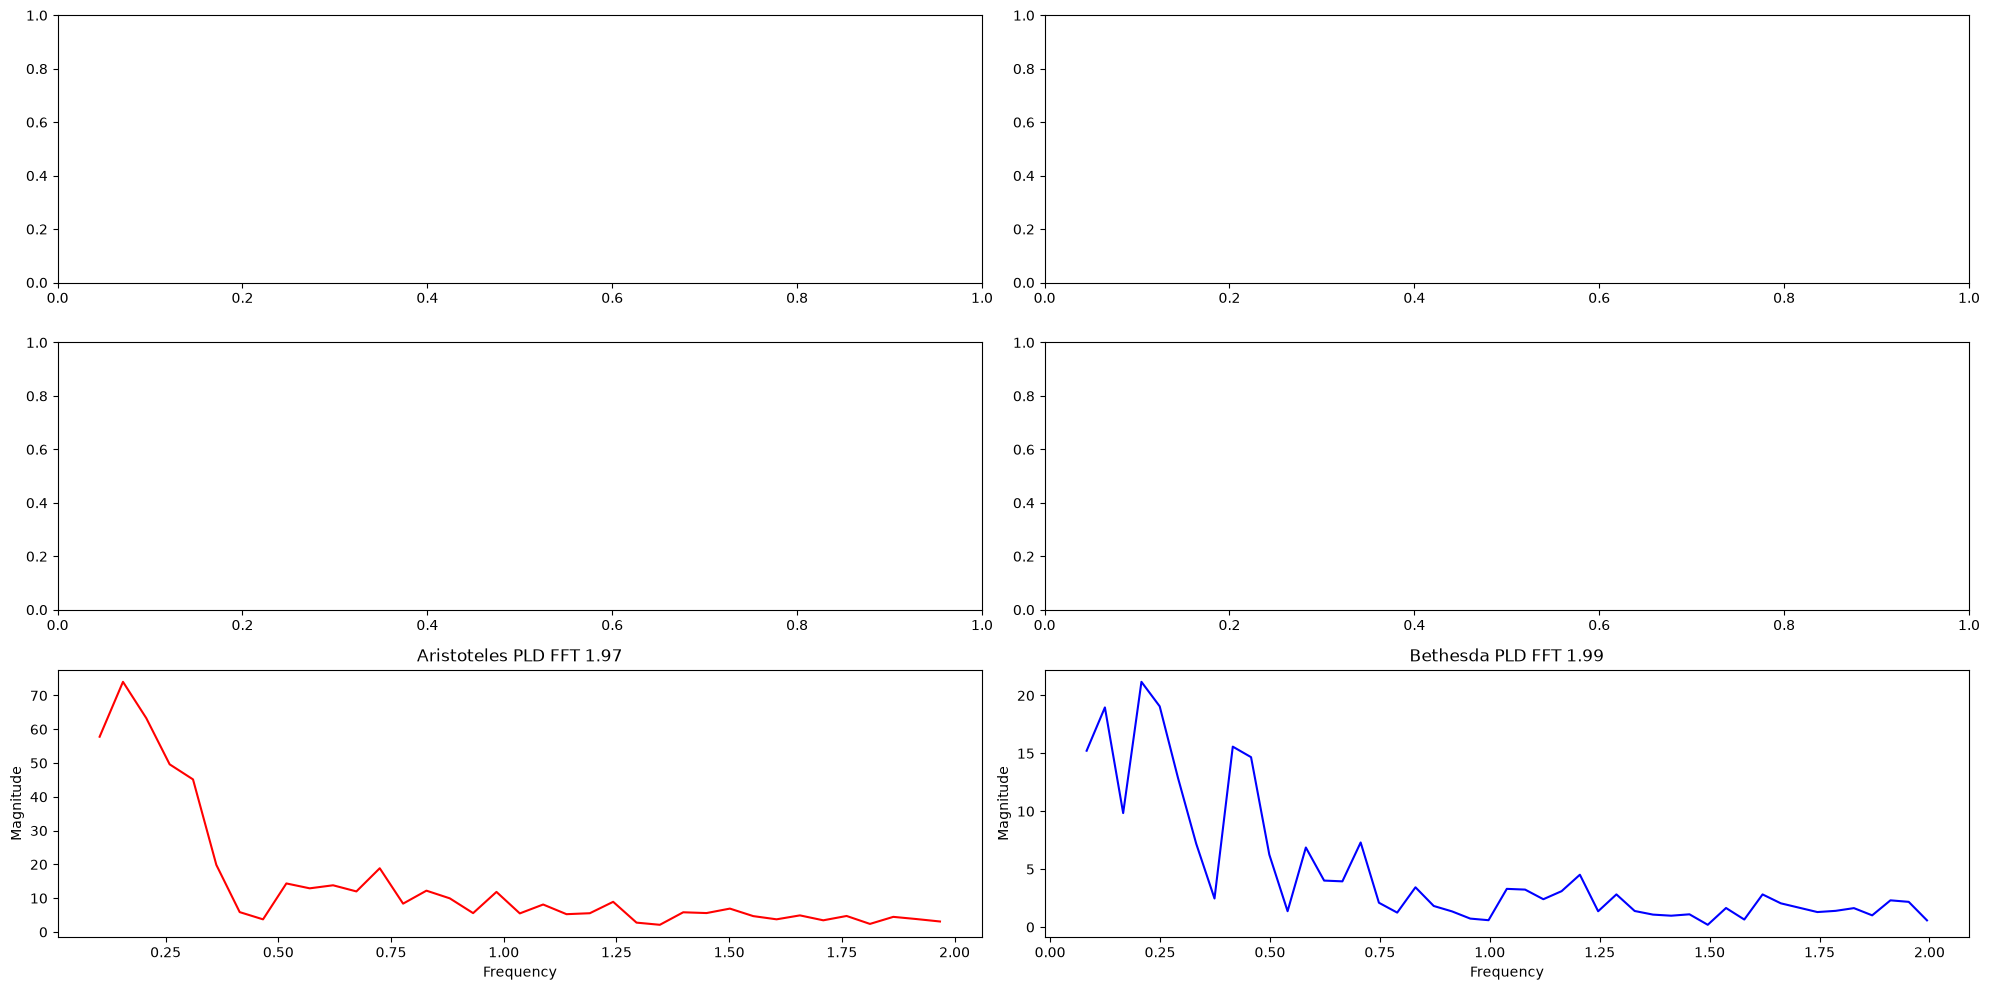

In [41]:
from cencalib import plot_fft

fig, ax = plt.subplots(3, 2, figsize=(20, 10))

aristoteles_default_freqs, aristoteles_default_mags = fft_lightcurve(lc_aristoteles_default.flux.value, lc_aristoteles_default.time.value)
aristoteles_cbvs_freqs, aristoteles_cbvs_mags = fft_lightcurve(lc_aristoteles_cbvs.flux.value, lc_aristoteles_cbvs.time.value)
aristoteles_pld_freqs, aristoteles_pld_mags = fft_lightcurve(lc_aristoteles_pld_small.flux.value, lc_aristoteles_pld_small.time.value, min_period=0.5, max_period=14.0)

bethesda_default_freqs, bethesda_default_mags = fft_lightcurve(lc_bethesda_default.flux.value, lc_bethesda_default.time.value)
bethesda_cbvs_freqs, bethesda_cbvs_mags = fft_lightcurve(lc_bethesda_cbvs.flux.value, lc_bethesda_cbvs.time.value)
bethesda_pld_freqs, bethesda_pld_mags = fft_lightcurve(lc_bethesda_pld_small.flux.value, lc_bethesda_pld_small.time.value, min_period=0.5, max_period=14.0)

n_samples_ari = len(aristoteles_default_freqs)
n_samples_bet = len(bethesda_default_freqs)

# plot_fft(aristoteles_default_freqs[:n_samples_ari], aristoteles_default_mags[:n_samples_ari], 'Aristoteles Default FFT', 'blue', ax[0, 0])
# plot_fft(bethesda_default_freqs[:n_samples_bet], bethesda_default_mags[:n_samples_bet], 'Bethesda Default FFT', 'blue', ax[0, 1])
# plot_fft(aristoteles_cbvs_freqs[:n_samples_ari], aristoteles_cbvs_mags[:n_samples_ari], 'Aristoteles CBVS FFT', 'green', ax[1, 0])
# plot_fft(bethesda_cbvs_freqs[:n_samples_bet], bethesda_cbvs_mags[:n_samples_bet], 'Bethesda CBVS FFT', 'green', ax[1, 1])
plot_fft(aristoteles_pld_freqs[:n_samples_ari], aristoteles_pld_mags[:n_samples_ari], 'Aristoteles PLD FFT', 'red', ax[2, 0])
plot_fft(bethesda_pld_freqs[:n_samples_bet], bethesda_pld_mags[:n_samples_bet], 'Bethesda PLD FFT', 'blue', ax[2, 1])

plt.tight_layout()
plt.show()


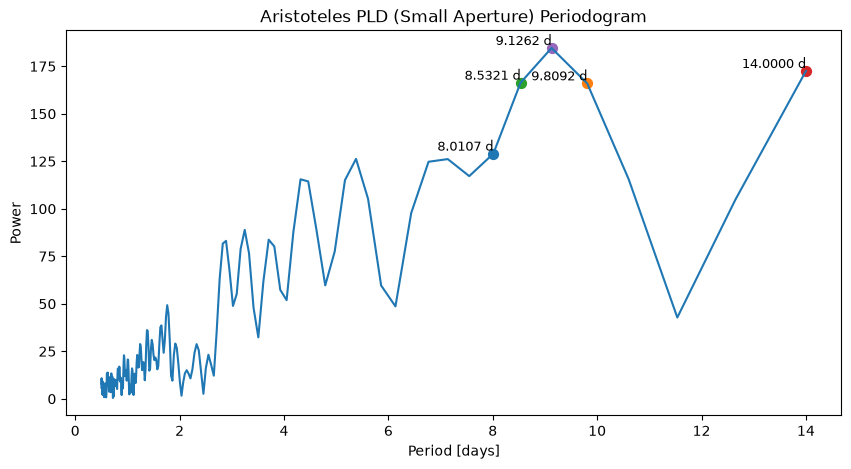

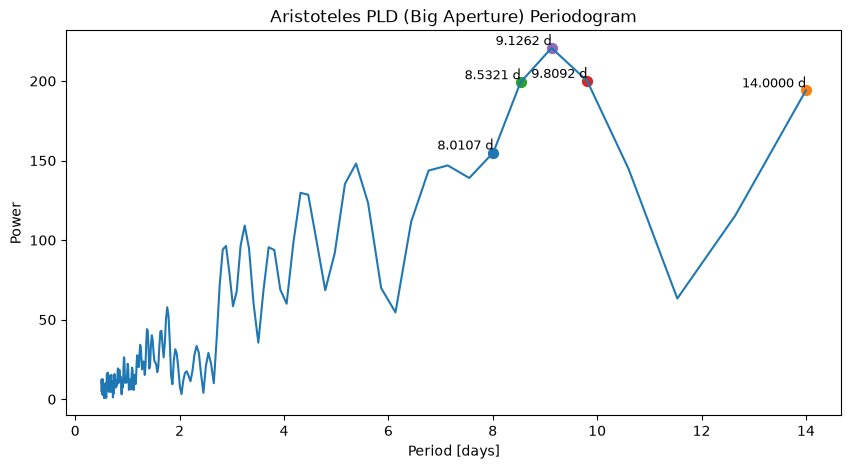

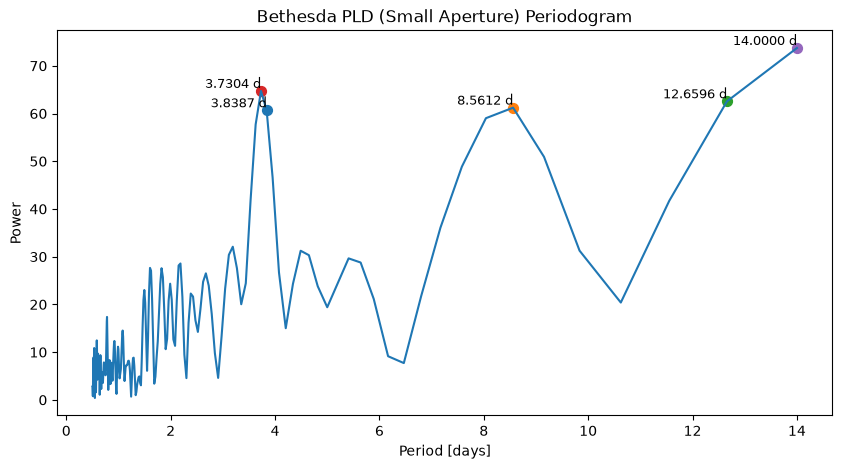

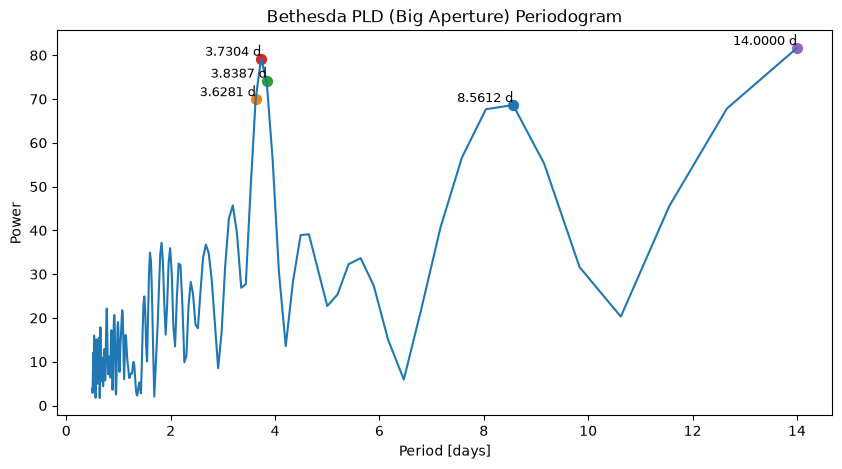

In [45]:
aristoteles_periodogram_small = lc_aristoteles_pld_small.to_periodogram(method="ls", minimum_period=0.5, maximum_period=14)
aristoteles_periodogram_big = lc_aristoteles_pld_big.to_periodogram(method="ls", minimum_period=0.5, maximum_period=14)
bethesda_periodogram_small = lc_bethesda_pld_small.to_periodogram(method="ls", minimum_period=0.5, maximum_period=14)
bethesda_periodogram_big = lc_bethesda_pld_big.to_periodogram(method="ls", minimum_period=0.5, maximum_period=14)

from cencalib import plot_significant_periods
plot_significant_periods(aristoteles_periodogram_small, "Aristoteles PLD (Small Aperture)")
plot_significant_periods(aristoteles_periodogram_big, "Aristoteles PLD (Big Aperture)")
plot_significant_periods(bethesda_periodogram_small, "Bethesda PLD (Small Aperture)")
plot_significant_periods(bethesda_periodogram_big, "Bethesda PLD (Big Aperture)")

In this section i will apply Phase Dispersion Minimization (PDM) (method found from the HMM article, Stellingwerf's method 1978 then it was improved by other researchers aka PDM2 method) to the light curves, this method is useful for finding periodic signals in unevenly spaced data (non-parametric method)

To understand this method, we can think of it as a method that tries to fold the light curve over a range of periods and then measure how well the data points align with each other, if the data points align well, it means that the period is likely to be correct, if they do not align well, it means that the period is likely to be incorrect.

In [46]:
from cencalib import process_pdm


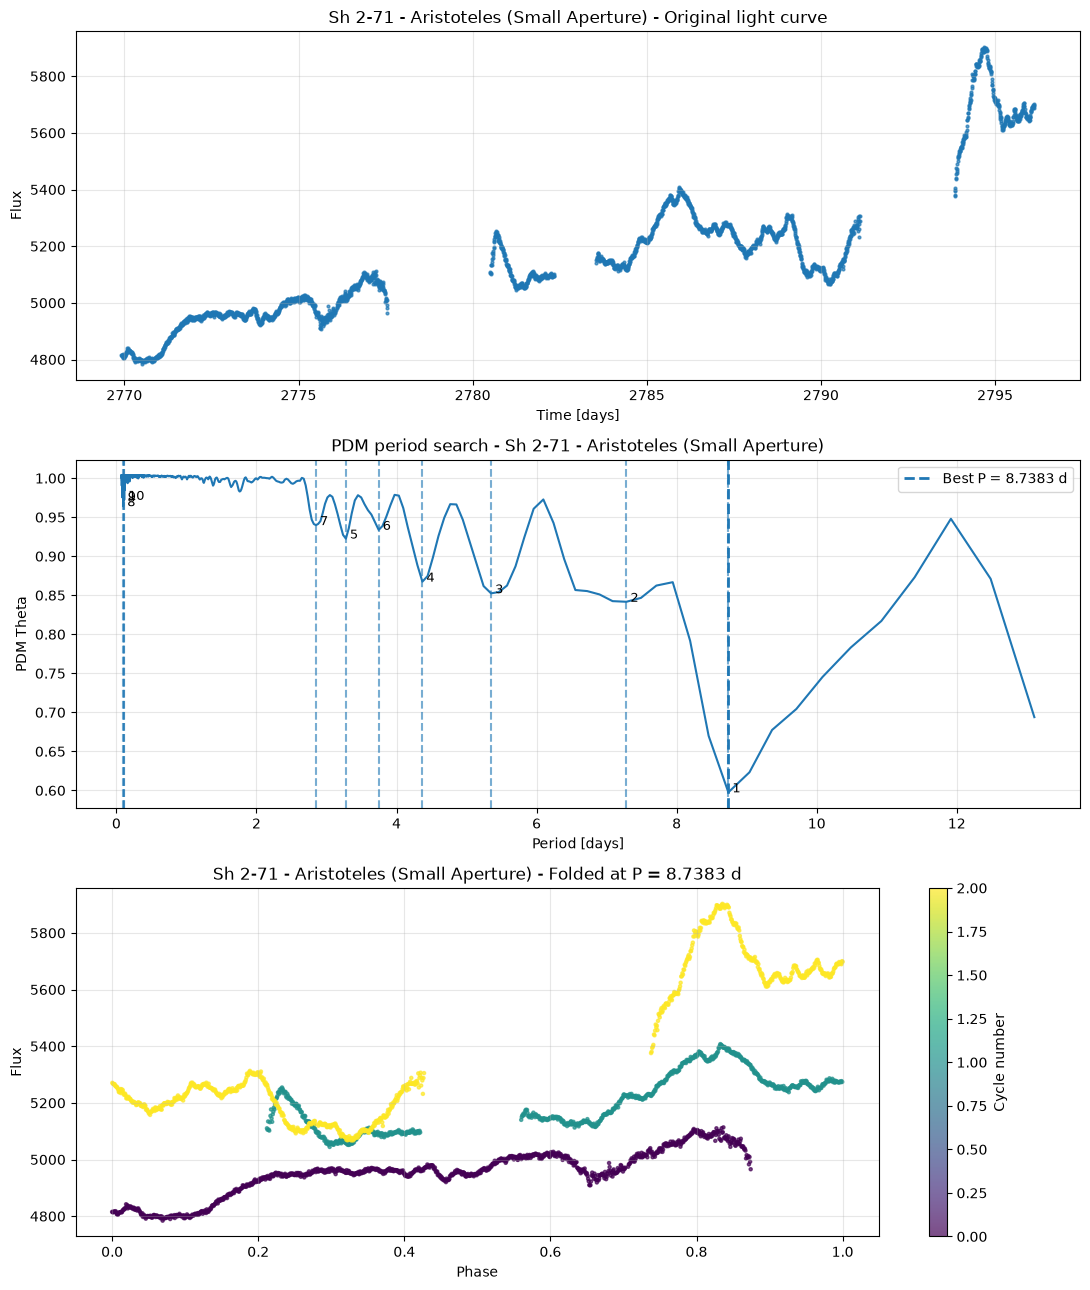

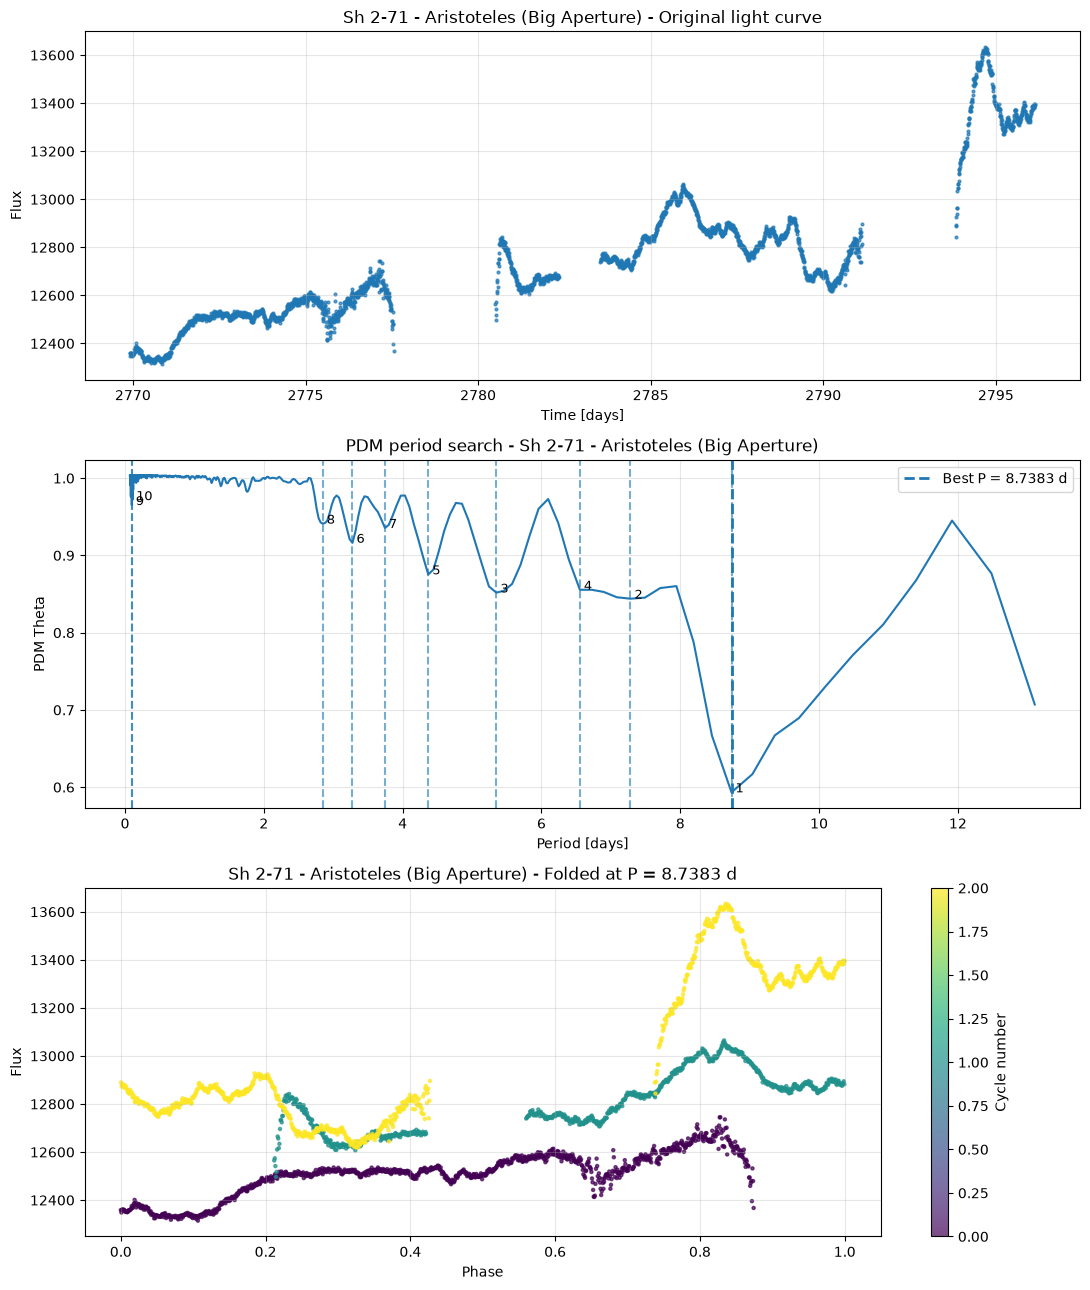

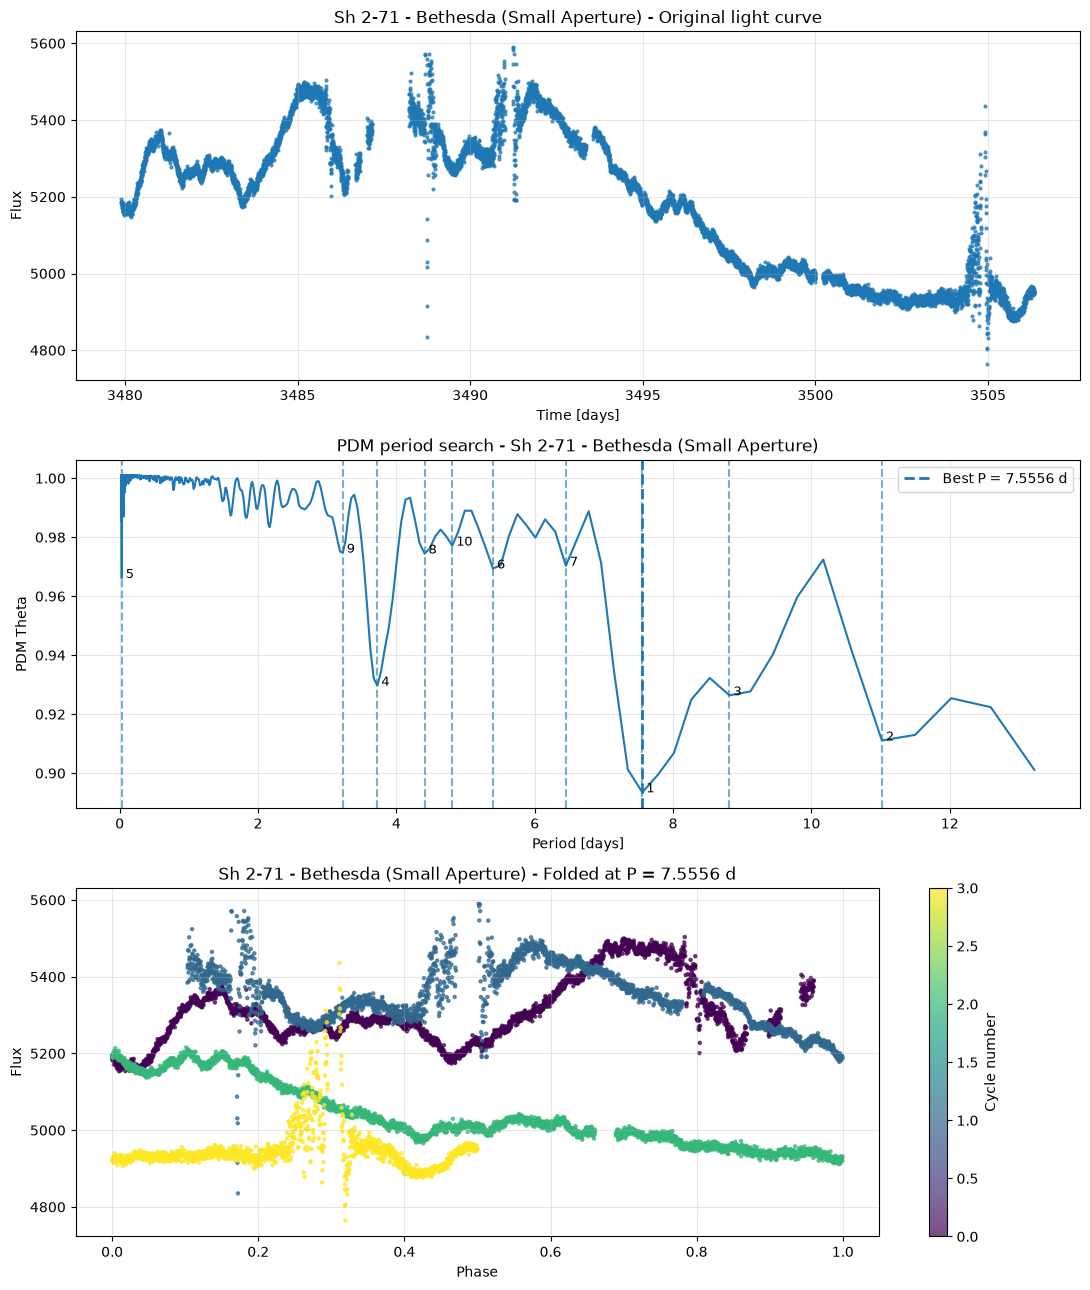

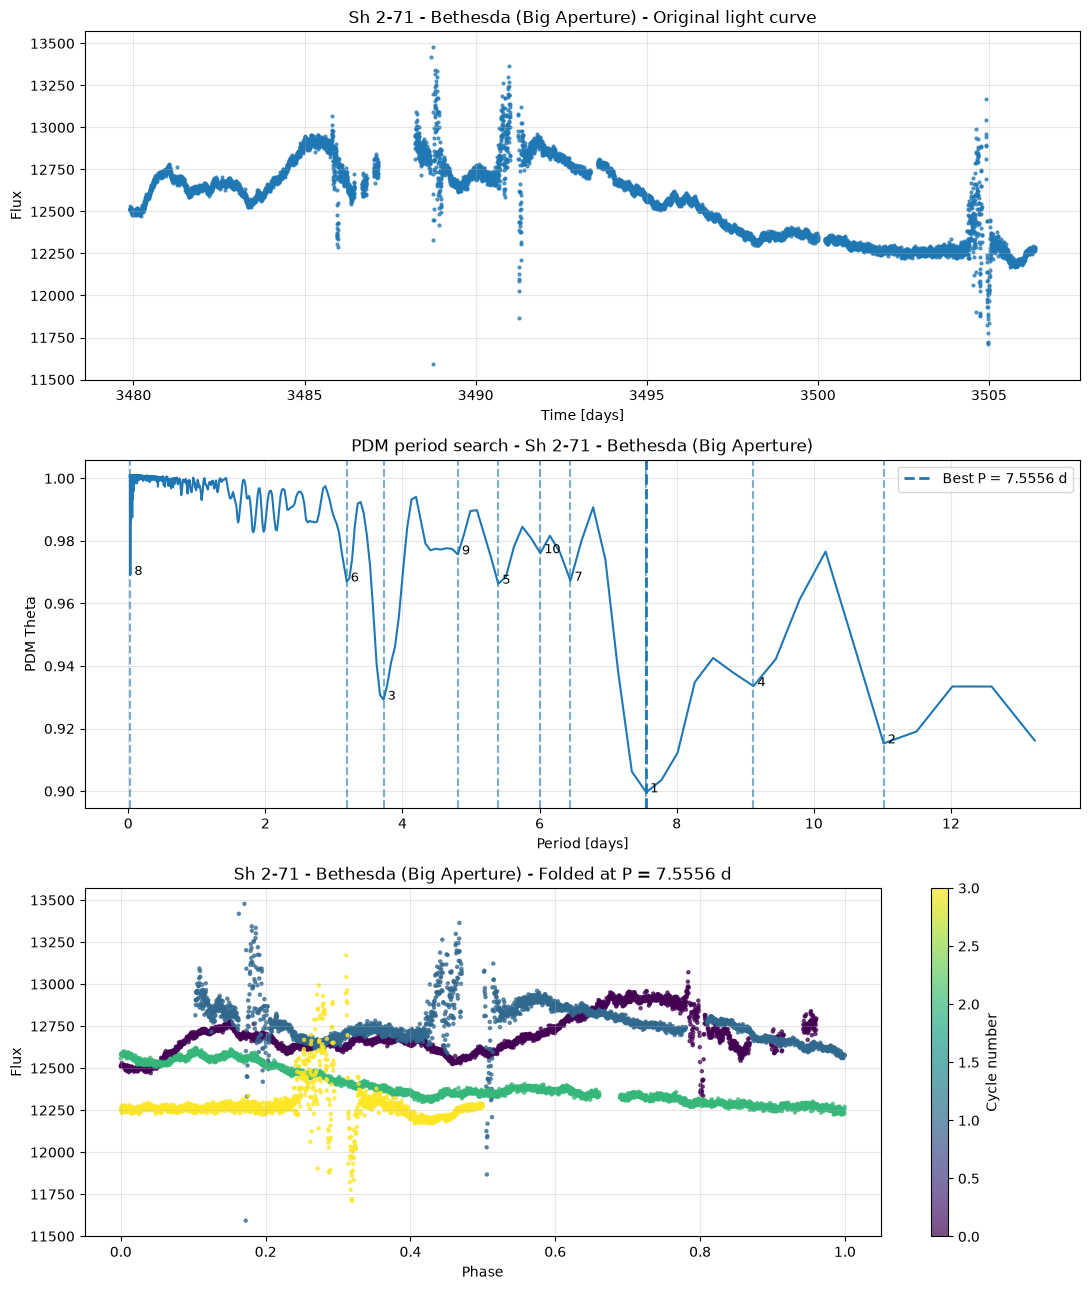

In [47]:
# The minimum period is constrained by the sampling cadence.
# The formal Nyquist limit would be:
#
#     P_min = 2 * cadence
#
# However, PDM benefits from having several samples per cycle.
# We therefore impose a more conservative minimum period.
#
# The maximum period is constrained by the observational baseline.
# We use:
#
#     P_max = baseline / 2
#
# so that every searched period contains at least approximately
# two cycles within the observations.

aristoteles_small_pdm = process_pdm(
    lc_aristoteles_pld_small.time.value,
    lc_aristoteles_pld_small.flux.value,
    n_bins=10,
    n_candidates=10,
    title="Sh 2-71 - Aristoteles (Small Aperture)"
)

aristoteles_big_pdm = process_pdm(
    lc_aristoteles_pld_big.time.value,
    lc_aristoteles_pld_big.flux.value,
    n_bins=10,
    n_candidates=10,
    title="Sh 2-71 - Aristoteles (Big Aperture)"
)

bethesda_small_pdm = process_pdm(
    lc_bethesda_pld_small.time.value,
    lc_bethesda_pld_small.flux.value,
    n_bins=10,
    n_candidates=10,
    title="Sh 2-71 - Bethesda (Small Aperture)"
)
bethesda_big_pdm = process_pdm(
    lc_bethesda_pld_big.time.value,
    lc_bethesda_pld_big.flux.value,
    n_bins=10,
    n_candidates=10,
    title="Sh 2-71 - Bethesda (Big Aperture)"
)

# Trends normalization
In this section i will aproximate long trends to the pld light curves and then remove them to again pass through the period analysis

In [48]:
from cencalib import identify_linear_trend


In [49]:
from cencalib import identify_cuadratic_trend


In [50]:
from cencalib import identify_cubic_trend


In [51]:
def identify_polynomial_trend(lc, degree=1):
    # least squares polynomial fit of specified degree
    time = lc.time.value
    flux = lc.flux.value

    # Create the Vandermonde matrix for polynomial fitting
    X_bias = np.vander(time, N=degree + 1, increasing=True)

    # Solve for the coefficients
    coeffs = np.linalg.lstsq(X_bias, flux, rcond=None)[0]

    # Calculate the fitted values
    fitted_values = np.polyval(coeffs[::-1], time)

    # Calculate the residuals
    residuals = flux - fitted_values

    return {"coefficients": coeffs, "fitted_values": fitted_values, "residuals": residuals}

## procesar

In [52]:
def plot_detrending(lc, trend_dict, title, color):
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))

    ax[0].scatter(lc.time.value, lc.flux.value, color=color, s=1)
    ax[0].plot(lc.time.value, trend_dict["fitted_values"], color='red', label='Fitted Trend')
    ax[0].set_title(f'{title} with Fitted Trend')
    ax[0].set_xlabel('Time (BTJD)')
    ax[0].set_ylabel('Flux')
    ax[0].legend()

    ax[1].scatter(lc.time.value, trend_dict["residuals"], color=color, s=1)
    ax[1].set_title(f'{title} Detrended Residuals')
    ax[1].set_xlabel('Time (BTJD)')
    ax[1].set_ylabel('Residuals')

    plt.tight_layout()
    plt.show()

{'coefficients': array([-7.02292903e+04,  2.70963380e+01]), 'fitted_values': array([4825.16825881, 4825.35642969, 4825.54460057, ..., 5535.12198705,
       5535.31015132, 5535.49831558], shape=(2781,)), 'residuals': array([ -9.82865824, -11.45359638, -11.4320553 , ..., 154.2695432 ,
       164.98454615, 162.47075204], shape=(2781,))}


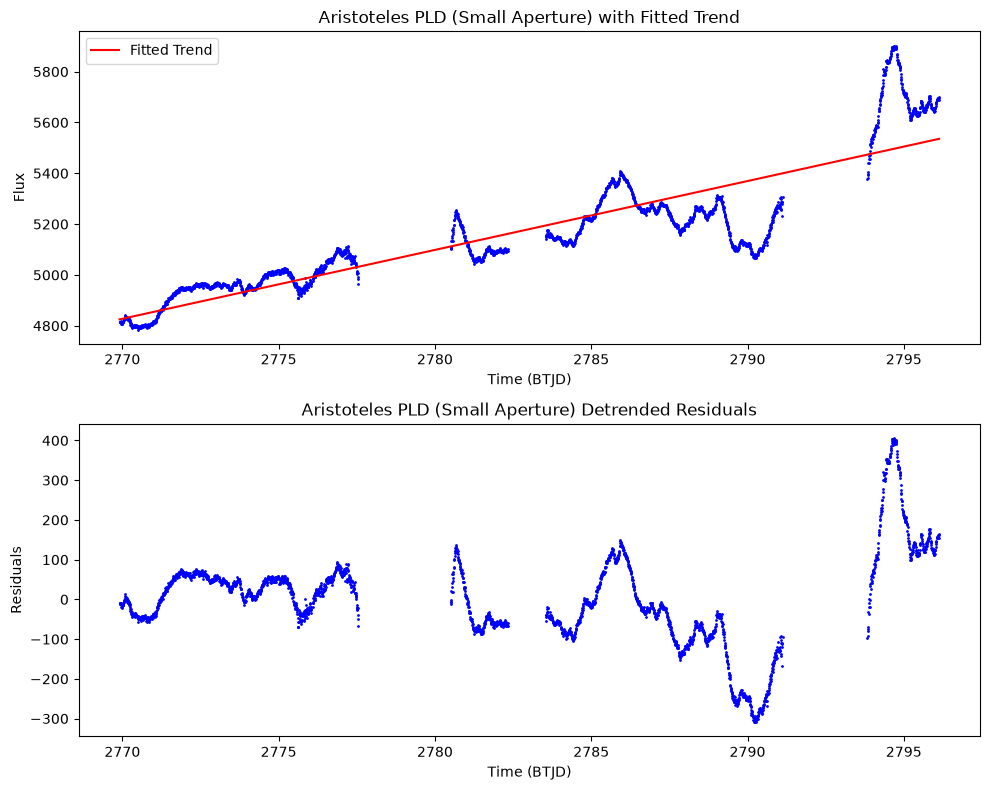

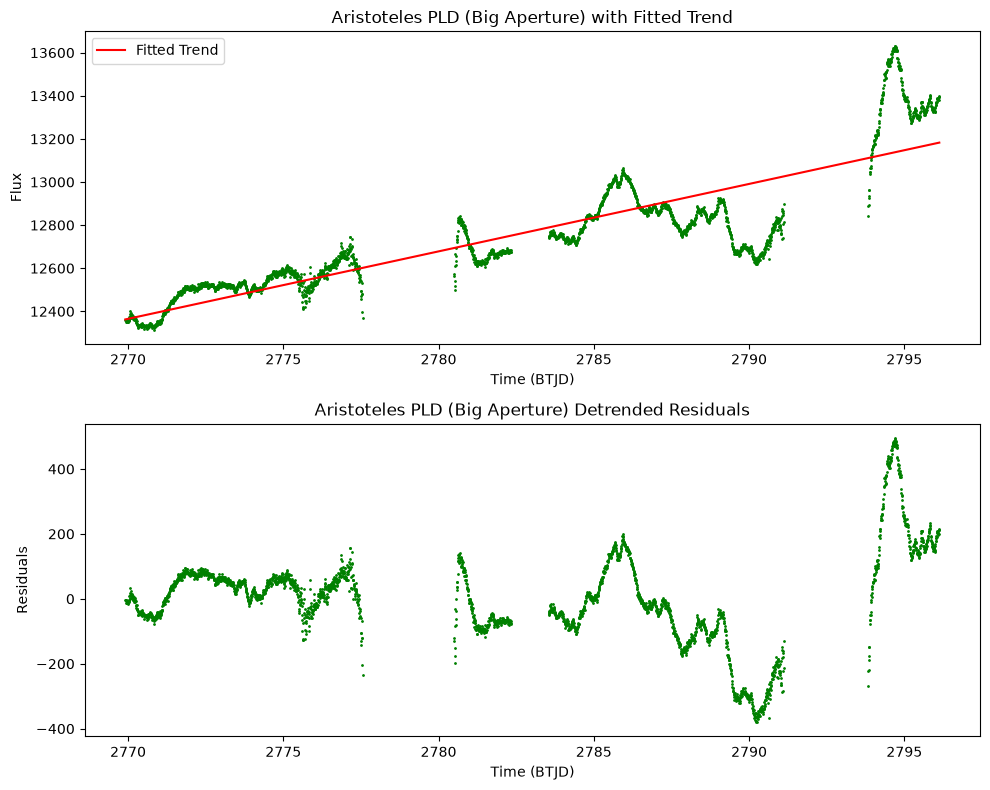

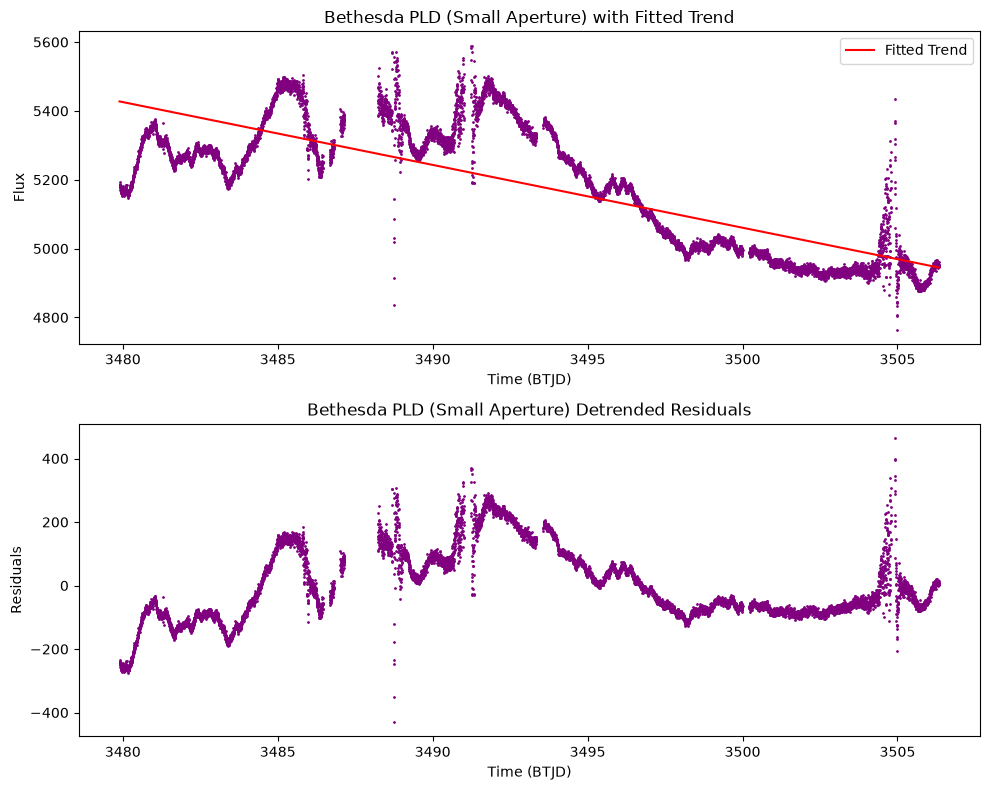

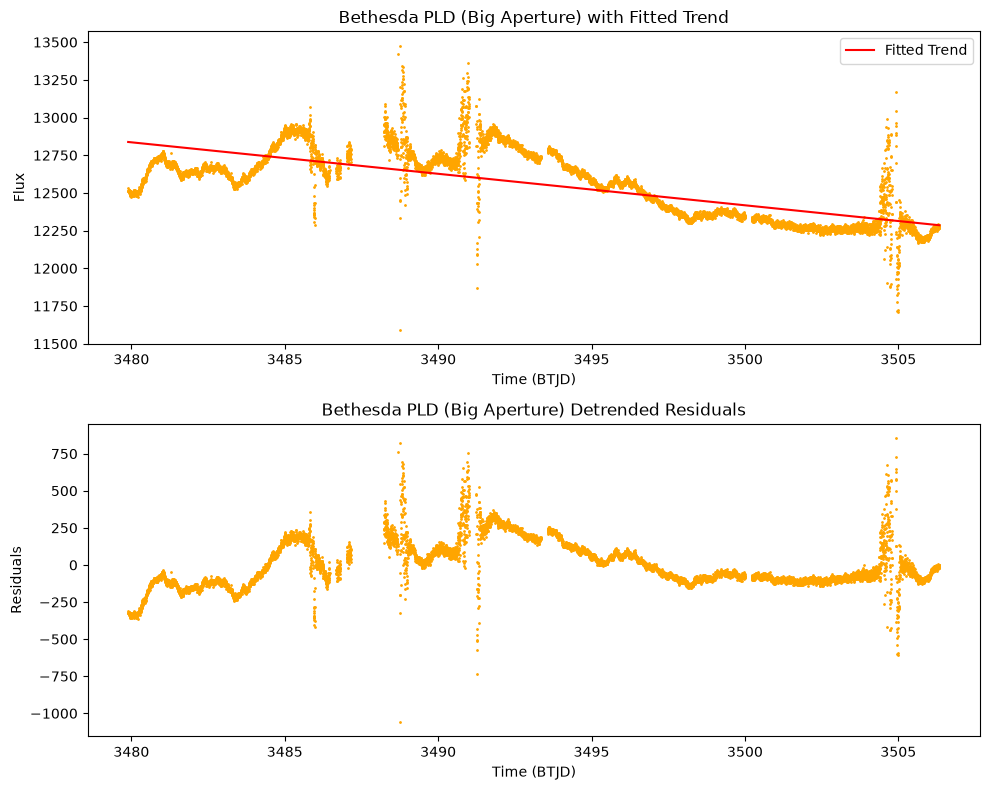

In [53]:
aristoteles_trend_small = identify_polynomial_trend(lc_aristoteles_pld_small)
aristoteles_trend_big = identify_polynomial_trend(lc_aristoteles_pld_big)
bethesda_trend_small = identify_polynomial_trend(lc_bethesda_pld_small)
bethesda_trend_big = identify_polynomial_trend(lc_bethesda_pld_big)

print(aristoteles_trend_small)

plot_detrending(lc_aristoteles_pld_small, aristoteles_trend_small, "Aristoteles PLD (Small Aperture)", "blue")
plot_detrending(lc_aristoteles_pld_big, aristoteles_trend_big, "Aristoteles PLD (Big Aperture)", "green")
plot_detrending(lc_bethesda_pld_small, bethesda_trend_small, "Bethesda PLD (Small Aperture)", "purple")
plot_detrending(lc_bethesda_pld_big, bethesda_trend_big, "Bethesda PLD (Big Aperture)", "orange")


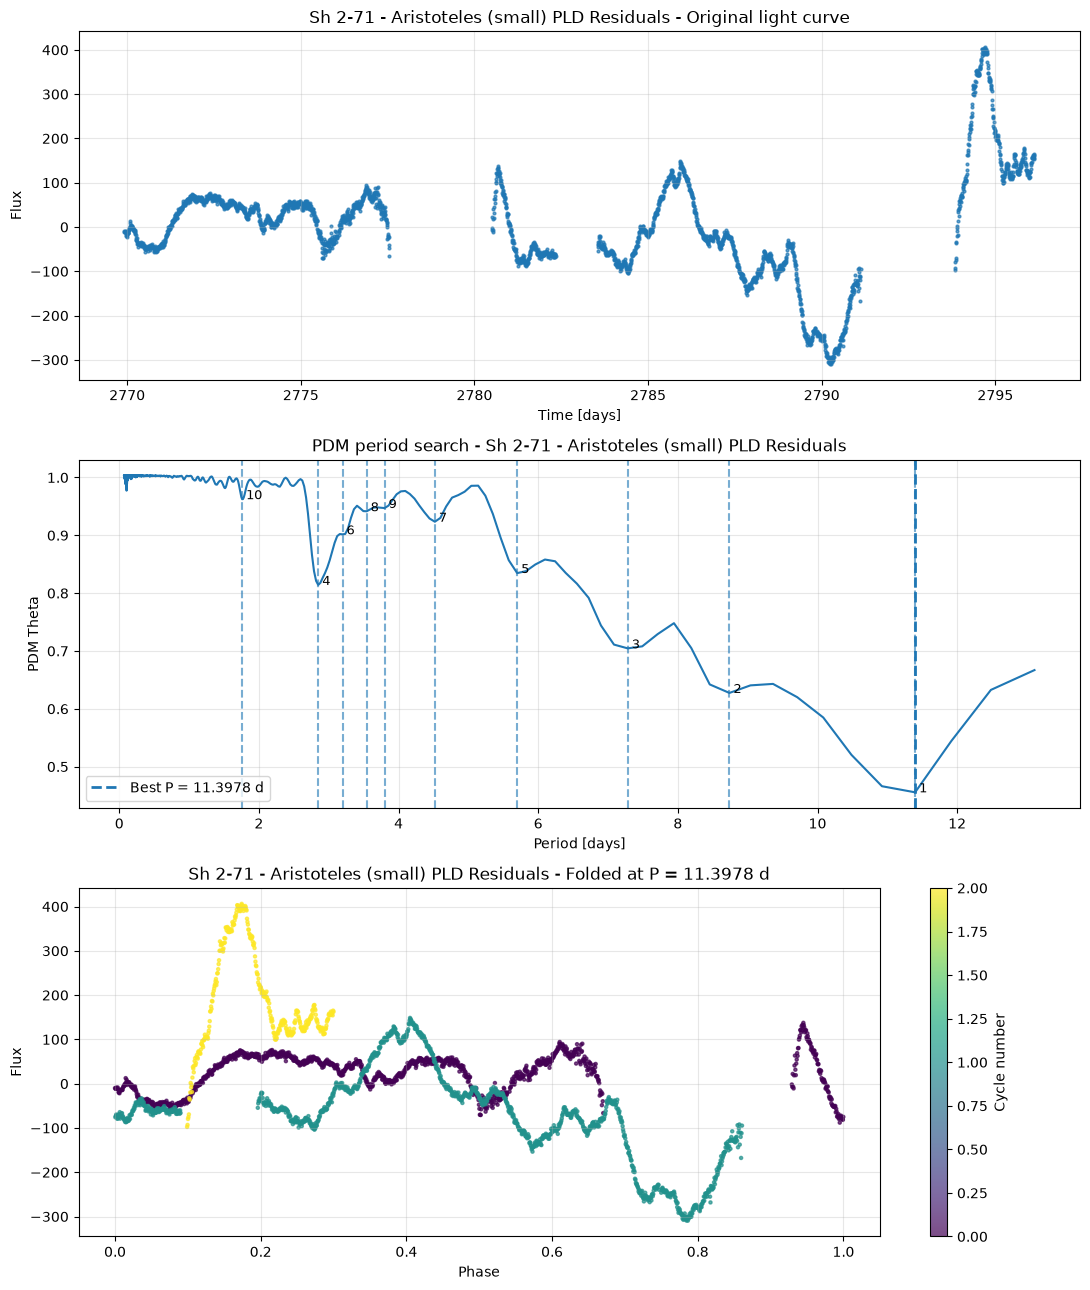

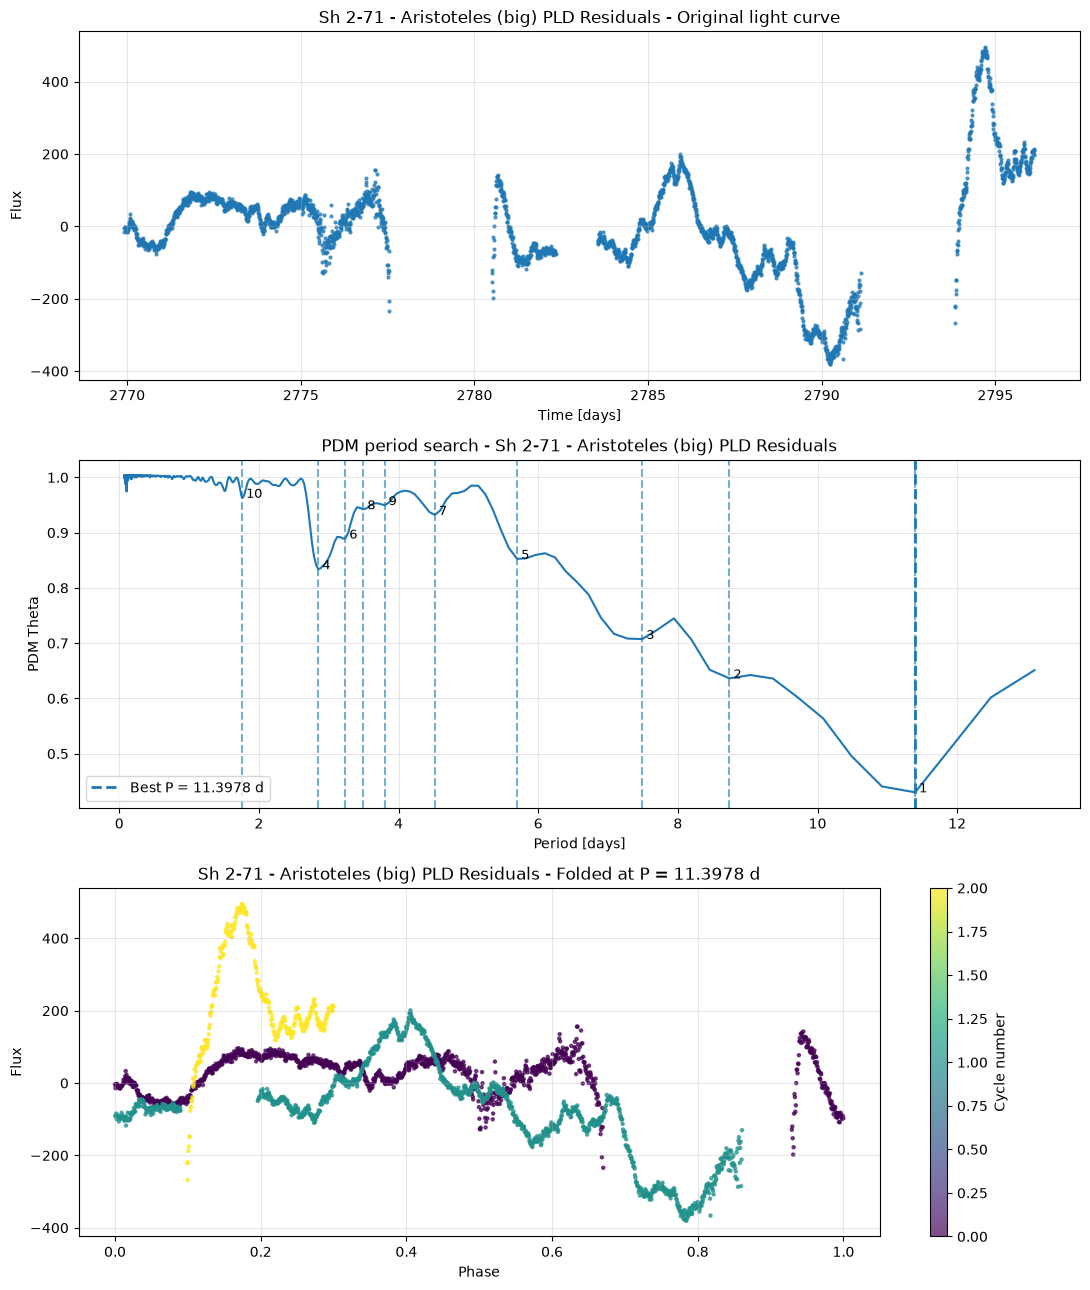

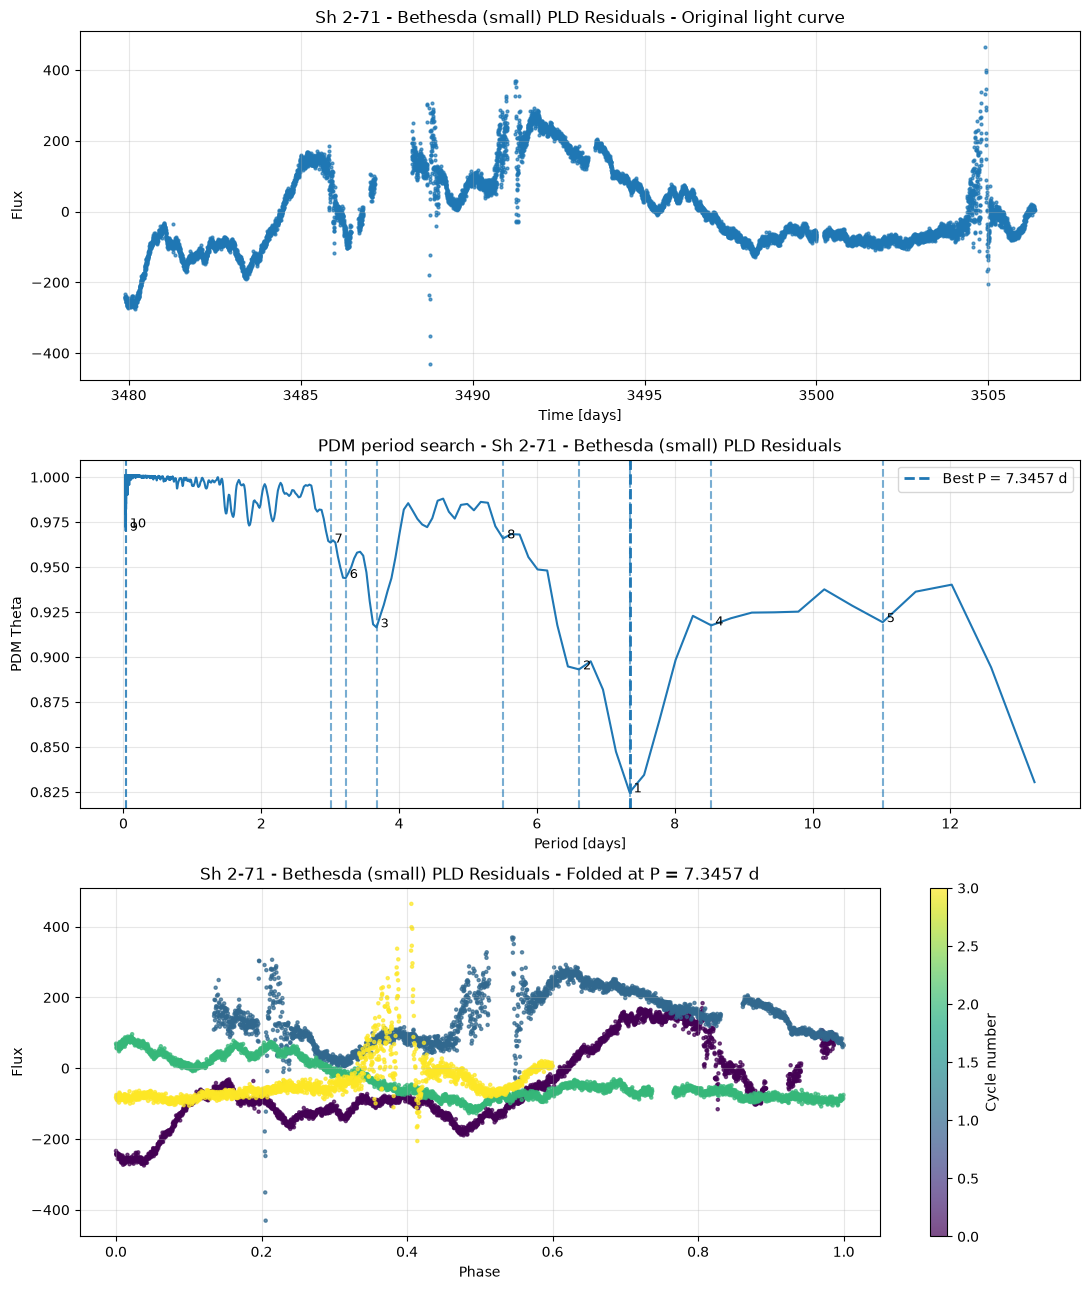

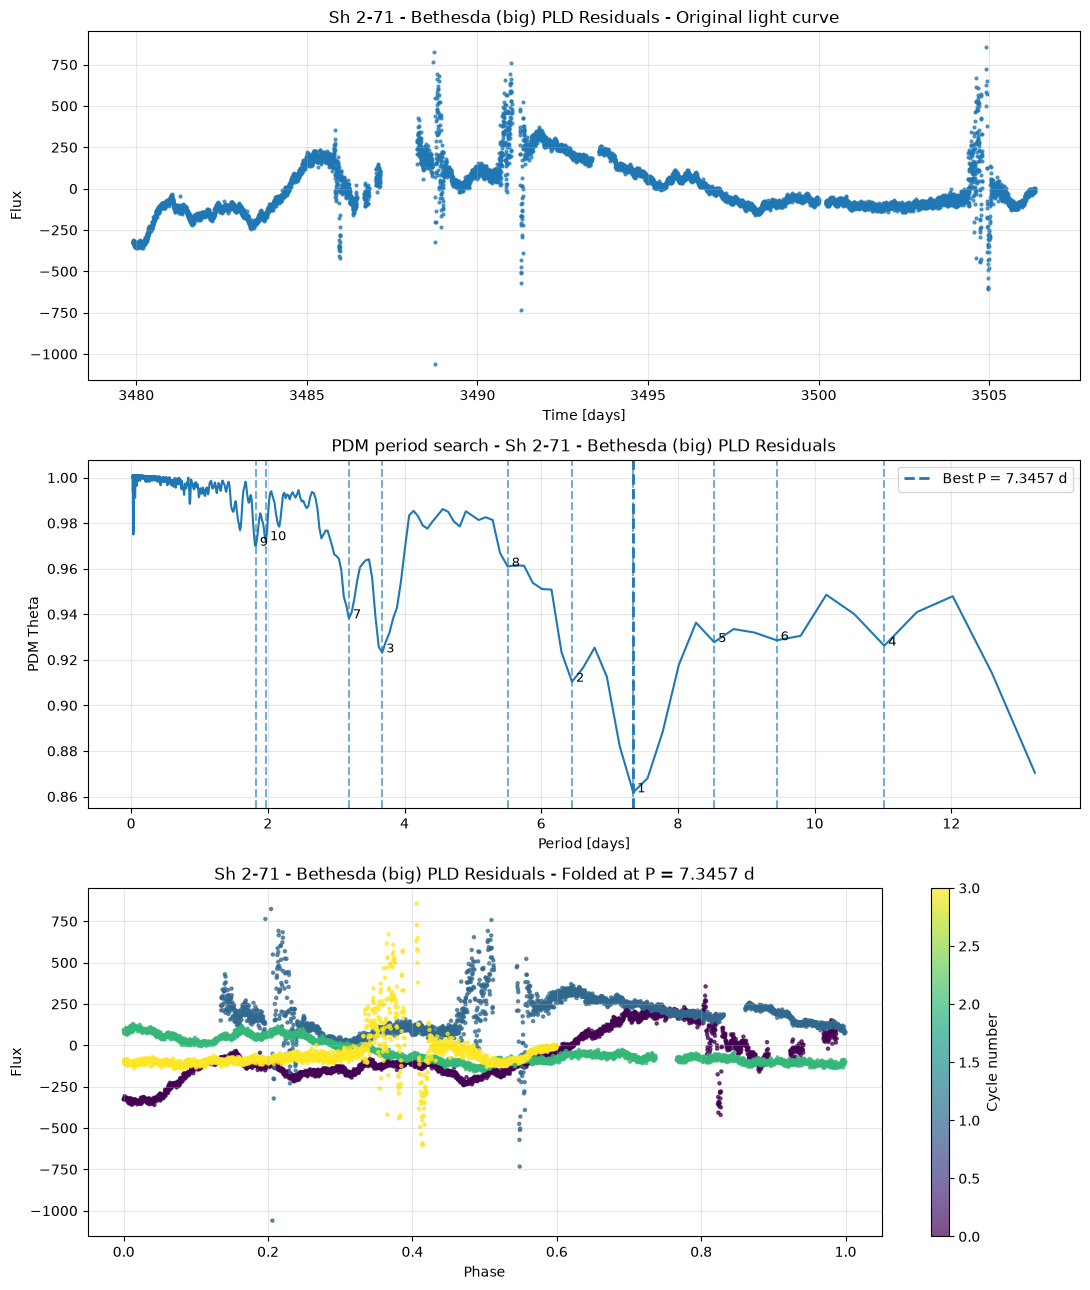

{'best_period': np.float64(7.345747511746796),
 'best_theta': np.float64(0.8618492985443208),
 'cycles_observed': np.float64(3.6),
 'period': array([ 0.02315039,  0.02315242,  0.02315444, ..., 12.02031411,
        12.59271002, 13.22234552], shape=(11404,)),
 'theta': array([1.00084622, 1.0008315 , 1.00083234, ..., 0.94791062, 0.91425186,
        0.87044604], shape=(11404,)),
 'candidate_periods': array([ 7.34574751,  6.44992464,  3.67287376, 11.01862127,  8.5305455 ,
         9.44453252,  3.18610735,  5.50931063,  1.8237718 ,  1.97348441]),
 'candidate_theta': array([0.8618493 , 0.91040557, 0.92322336, 0.92621476, 0.92776065,
        0.92857788, 0.93822187, 0.96094507, 0.97001951, 0.97249199]),
 'baseline': np.float64(26.44469104228847),
 'sampling_duration': np.float64(0.002314842126907024),
 'min_period': np.float64(0.02314842126907024),
 'max_period': np.float64(13.222345521144234)}

In [54]:

process_pdm(lc_aristoteles_pld_small.time.value, aristoteles_trend_small["residuals"], n_bins=10, n_candidates=10, title="Sh 2-71 - Aristoteles (small) PLD Residuals")
process_pdm(lc_aristoteles_pld_big.time.value, aristoteles_trend_big["residuals"], n_bins=10, n_candidates=10, title="Sh 2-71 - Aristoteles (big) PLD Residuals")
process_pdm(lc_bethesda_pld_small.time.value, bethesda_trend_small["residuals"], n_bins=10, n_candidates=10, title="Sh 2-71 - Bethesda (small) PLD Residuals")
process_pdm(lc_bethesda_pld_big.time.value, bethesda_trend_big["residuals"], n_bins=10, n_candidates=10, title="Sh 2-71 - Bethesda (big) PLD Residuals")
